In [39]:
import numpy as np
from matplotlib import pyplot as plt
from cycler import cycler
plt.rc('axes', prop_cycle=cycler(color=['0.0', '0.4', '0.8']))
import matplotlib; matplotlib.rcParams.update({'font.size': 18})

In [40]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import course_helpers as chh
import ml_helpers as mlh
apply_beamer_theme(
    "madrid", skip_font_download=True, author="Robert Pettis", date="Fall 2026",
    show_slide_number=True, cell_tags=True, notebook_path="19-Causal-Forests.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 34 cell(s):
 cell_index   slide_id                                  tags
         11  slide-1-2 slide_hide_prompt, slide_remove_input
         13  slide-1-3 slide_hide_prompt, slide_remove_input
         15  slide-1-4 slide_hide_prompt, slide_remove_input
         17  slide-1-5 slide_hide_prompt, slide_remove_input
         19  slide-1-6 slide_hide_prompt, slide_remove_input
         21  slide-1-7 slide_hide_prompt, slide_remove_input
         23  slide-1-8 slide_hide_prompt, slide_remove_input
         25  slide-1-9 slide_hide_prompt, slide_remove_input
         27 slide-1-10 slide_hide_prompt, slide_remove_input
         30 slide-1-12 slide_hide_prompt, slide_remove_input
         32 slide-1-13 slide_hide_prompt, slide_remove_input
         34  slide-2-0 slide_hide_prompt, slide_remove_input
         39  slide-2-3 slide_hide_prompt, slide_remove_input
         41  slide-2-4 slide_hide_prompt, slide_remove_input
         44  slide-3-1 slide_hide_prompt, sli

In [41]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

In [42]:
# One place that knows the eight people, how to read an effect off a group
# of them, how to score a split, and how to draw the tables and trees. Every
# slide below supplies only its own numbers.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import course_helpers as chh

Q_FILL, LEAF_FILL = chh.ACCENT, "#2E8B57"
GREY_HEAD, GREY_TEXT = "#AEB4C7", "#C2C6D2"

# ------------------------------------------------------------ the eight people
HEAD = ["Age", "Diploma", "Female", "Trained", "Earnings\n($000)"]
HD_HEAD = HEAD
ROWS = [("22", "Yes", "No",  "Yes", "45"),
        ("25", "No",  "Yes", "Yes", "37"),
        ("27", "Yes", "Yes", "No",  "34"),
        ("29", "No",  "No",  "No",  "29"),
        ("34", "Yes", "Yes", "Yes", "35"),
        ("41", "No",  "No",  "Yes", "33"),
        ("47", "Yes", "No",  "No",  "36"),
        ("55", "No",  "Yes", "No",  "27")]
AGE = np.array([float(r[0]) for r in ROWS])
DIP = np.array([r[1] == "Yes" for r in ROWS])
FEM = np.array([r[2] == "Yes" for r in ROWS])
TRN = np.array([r[3] == "Yes" for r in ROWS])
EARN = np.array([float(r[4]) for r in ROWS])
ALL = np.ones(8, bool)
BLANK = ("", "", "", "", "")
COLHEAD = {3: chh.ACCENT}          # the trained column keeps a colour of its own


def effect(m, y=EARN, t=TRN):
    """The number a causal tree writes in a leaf: average earnings of the
       people in the group who trained, minus those who did not. None when
       one of the two is missing, since then there is nothing to compare."""
    if not (m & t).any() or not (m & ~t).any():
        return None
    return y[m & t].mean() - y[m & ~t].mean()


def gain(masks, y=EARN, t=TRN, leaf=None):
    """How far the leaf effects sit from the effect before the split,
       each weighted by headcount and added up. leaf: what a leaf holds,
       trained minus not unless centering swaps it."""
    leaf = effect if leaf is None else leaf
    parent = np.zeros(len(y), bool)
    for m in masks:
        parent |= m
    before = leaf(parent, y, t)
    total = 0.0
    for m in masks:
        e = leaf(m, y, t)
        if e is None:
            return None
        total += m.sum() * (e - before) ** 2
    return total


def midpoints(a):
    s = np.sort(np.unique(a))
    return (s[:-1] + s[1:]) / 2


def allowed(masks, y=EARN, t=TRN, least=2):
    """A leaf has to hold at least `least` people who trained and `least`
       who did not, or its effect is a guess."""
    return all((m & t).sum() >= least and (m & ~t).sum() >= least for m in masks)


def fmt(v):
    return "none" if v is None else ("%+g" % round(v, 2))


def lst(m, arm):
    return ", ".join("%.0f" % v for v in EARN[m & (TRN if arm else ~TRN)])

def blank_ax(ax):
    ax.set_facecolor("white")
    ax.axis("off")


def data_table(ax, rows, head=None, left=0.0, top=0.0, cw=1.18, rh=0.50,
               hh=1.05, target=4, grey=(), ring_rows=(), ring_cols=(),
               fs=8.5, caption=None, head_colors=None, ring_cells=()):
    """One of his tables, drawn in data units so a tree can sit beside it.
       grey: columns already used, faded out. ring_rows, ring_cols and
       ring_cells: what the red circle is around on this slide."""
    head = HD_HEAD if head is None else head
    n = len(head)
    for j, h in enumerate(head):
        fc = (GREY_HEAD if j in grey else
              chh.FITLINE if j == target else chh.MADRID)
        fc = (head_colors or {}).get(j, fc)
        ax.add_patch(plt.Rectangle((left + j * cw, top - hh), cw, hh,
                                   facecolor=fc, edgecolor="white", lw=1.2,
                                   zorder=3))
        ax.text(left + (j + .5) * cw, top - hh / 2, h, ha="center", va="center",
                fontsize=fs - 0.8, color="white", weight="bold", zorder=4,
                linespacing=1.15)
    for i, row in enumerate(rows):
        yb = top - hh - (i + 1) * rh
        for j in range(n):
            ax.add_patch(plt.Rectangle((left + j * cw, yb), cw, rh,
                                       facecolor="#EEF1F8" if i % 2 else "#FFFFFF",
                                       edgecolor="white", lw=1.0, zorder=3))
            v = str(row[j]) if j < len(row) else ""
            ax.text(left + (j + .5) * cw, yb + rh / 2, v, ha="center",
                    va="center", fontsize=fs, zorder=4,
                    color=GREY_TEXT if j in grey else chh.INK)
    for i in ring_rows:
        yb = top - hh - (i + 1) * rh
        ax.add_patch(FancyBboxPatch((left + .05, yb + .05), n * cw - .10,
                                    rh - .10, boxstyle="round,pad=0.04",
                                    facecolor="none", edgecolor=chh.FITLINE,
                                    lw=2.0, zorder=6))
    for j in ring_cols:
        ax.add_patch(FancyBboxPatch((left + j * cw + .06, top - hh + .06),
                                    cw - .12, hh - .12,
                                    boxstyle="round,pad=0.04", facecolor="none",
                                    edgecolor=chh.FITLINE, lw=2.2, zorder=6))
    for i, j in ring_cells:
        ax.add_patch(FancyBboxPatch((left + j * cw + .06,
                                     top - hh - (i + 1) * rh + .05),
                                    cw - .12, rh - .10,
                                    boxstyle="round,pad=0.03", facecolor="none",
                                    edgecolor=chh.FITLINE, lw=2.0, zorder=6))
    if caption:
        ax.text(left + n * cw / 2, top + .16, caption, ha="center", va="bottom",
                fontsize=fs + 2.0, color=chh.MADRID, weight="bold")
    return dict(left=left, right=left + n * cw, top=top,
                bottom=top - hh - len(rows) * rh, cw=cw, rh=rh, hh=hh,
                row=lambda i: top - hh - (i + .5) * rh,
                col=lambda j: left + (j + .5) * cw)


def node_box(ax, x, y, label, kind="q", fs=9.0, w=None, h=0.44, ring=False):
    """A single tree node, placed where you ask rather than where a layout
       engine wants it, so tables and trees can share one picture."""
    if w is None:
        w = 0.155 * max(len(t) for t in label.split("\n")) + 0.55
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h,
                                boxstyle="round,pad=0.08",
                                facecolor=Q_FILL if kind == "q" else LEAF_FILL,
                                edgecolor=chh.FITLINE if ring else chh.INK,
                                lw=2.4 if ring else 1.2, zorder=4))
    ax.text(x, y, label, ha="center", va="center", fontsize=fs, color="white",
            weight="bold", zorder=5, linespacing=1.1)
    return w


def link(ax, a, b, label=None, red=False, fs=7.5, h=0.60):
    """An arrow from the bottom of one node to the top of the next."""
    col = chh.FITLINE if red else chh.INK
    ax.annotate("", xy=(b[0], b[1] + h / 2), xytext=(a[0], a[1] - h / 2),
                arrowprops=dict(arrowstyle="-|>", color=col, mutation_scale=13,
                                lw=2.2 if red else 1.4), zorder=6)
    if label:
        ax.text((a[0] + b[0]) / 2 + (-.18 if b[0] < a[0] else .18),
                (a[1] + b[1]) / 2, label, ha="center", va="center", fontsize=fs,
                color=col, zorder=8,
                bbox=dict(boxstyle="round,pad=0.14", facecolor="white",
                          edgecolor="none"))


def curve(ax, frm, to, rad=-0.3, red=True, lw=1.6):
    """The red swoop he draws from a row to where it lands."""
    ax.annotate("", xy=to, xytext=frm, zorder=7,
                arrowprops=dict(arrowstyle="-|>", lw=lw,
                                color=chh.FITLINE if red else chh.INK,
                                connectionstyle="arc3,rad=%g" % rad))


def mini_tree(ax, ox, oy, seed, pitch=0.56, drop=0.50, bw=0.38, bh=0.16):
    """One of the small nameless trees a forest is drawn as. Orange asks,
       green answers. The shape is random, so no two of them match. ox is the
       centre of the tree, not its left edge, so a row of them lines up."""
    for attempt in range(40):
        rng = np.random.default_rng(seed + 1000 * attempt)
        nodes, edges, order = [], [], []

        def grow(depth):
            i = len(nodes)
            nodes.append([0.0, depth, "leaf"])
            chance = 1.0 if depth == 0 else (0.62 if depth == 1 else 0.28)
            if depth < 3 and rng.random() < chance:
                nodes[i][2] = "q"
                for _ in range(2):
                    edges.append((i, grow(depth + 1)))
            return i

        grow(0)

        def place(i):
            kids = [b for a, b in edges if a == i]
            if not kids:
                nodes[i][0] = float(len(order))
                order.append(i)
            else:
                for b in kids:
                    place(b)
                nodes[i][0] = sum(nodes[b][0] for b in kids) / len(kids)

        place(0)
        if 3 <= len(order) <= 5:
            break

    span = float(len(order) - 1)
    deep = max(n[1] for n in nodes)

    def xy(n):
        return ox + (n[0] - span / 2) * pitch, oy - n[1] * drop

    for a, b in edges:
        x1, y1 = xy(nodes[a])
        x2, y2 = xy(nodes[b])
        ax.annotate("", xy=(x2, y2 + bh / 2), xytext=(x1, y1 - bh / 2),
                    arrowprops=dict(arrowstyle="-|>", color=chh.INK, lw=1.0,
                                    mutation_scale=7))
    for n in nodes:
        x, y = xy(n)
        ax.add_patch(plt.Rectangle((x - bw / 2, y - bh / 2), bw, bh, zorder=4,
                                   facecolor=Q_FILL if n[2] == "q" else LEAF_FILL,
                                   edgecolor=chh.INK, lw=0.6))
    return dict(left=ox - (span / 2) * pitch - bw / 2, top=oy + bh / 2,
                right=ox + (span / 2) * pitch + bw / 2, mid=ox,
                bottom=oy - deep * drop - bh / 2)


def frame(figsize, xlim, ylim, dpi=110):
    """A blank white panel with the limits set by hand, since these pictures
       are laid out in data units and must not be autoscaled."""
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    fig.patch.set_facecolor("white")
    blank_ax(ax)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    return fig, ax


def note(ax, x, y, text, fs=10.0, ha="left", va="center", color=None):
    ax.text(x, y, text, ha=ha, va=va, fontsize=fs, linespacing=1.35,
            color=color or chh.INK, zorder=8)




def colored_note(ax, x, y, pieces, fs=10.0, ha="center", va="center"):
    """One line of text in more than one color. pieces is a list of
       (text, color) pairs; the renderer measures each piece so the next
       one starts where it ends. None means the ink color."""
    rend = ax.figure.canvas.get_renderer()
    to_data = ax.transData.inverted()
    texts, widths = [], []
    for s, c in pieces:
        t = ax.text(x, y, s, ha="left", va=va, fontsize=fs, color=c or chh.INK, zorder=8)
        bb = t.get_window_extent(renderer=rend)
        widths.append(to_data.transform((bb.x1, 0))[0] - to_data.transform((bb.x0, 0))[0])
        texts.append(t)
    total = sum(widths)
    left = {"center": x - total / 2, "right": x - total, "left": x}[ha]
    for t, w in zip(texts, widths):
        t.set_x(left)
        left += w


def split_picture(question, left, right, ring_col=None, rows=None, note_text=None,
                  least=1, figsize=(12.6, 4.4)):
    """The table on the right with one column ringed, and on the left the
       question with its two leaves, each leaf carrying its effect and the
       earnings it was computed from."""
    rows = ROWS if rows is None else rows
    fig, ax = frame(figsize, (-6.6, 7.8), (-4.3, 0.9))
    data_table(ax, rows, left=1.2, top=0.2, caption="Original Dataset",
               ring_cols=[] if ring_col is None else [ring_col], head_colors=COLHEAD)
    node_box(ax, -3.6, -0.25, question, fs=10.5)
    for s, m, side in ((-1, left, "True"), (1, right, "False")):
        x = -3.6 + s * 2.3
        ok = allowed([m], least=least)
        e = effect(m) if ok else None
        link(ax, (-3.6, -0.25), (x, -1.55), side)
        node_box(ax, x, -1.55, "effect\n%s" % ("?" if e is None else "%+g" % round(e, 2)),
                 kind="leaf", w=1.9, fs=11.5, ring=not ok)
        note(ax, x, -2.55, "trained:  " + (lst(m, True) or "nobody"), fs=10.5,
             ha="center", color=chh.ACCENT)
        note(ax, x, -2.95, "did not:  " + (lst(m, False) or "nobody"), fs=10.5,
             ha="center", color=chh.MADRID)
    if note_text:
        note(ax, -3.6, -3.85, note_text, fs=11, ha="center", color=chh.FITLINE)
    return fig, ax


def effect_box(ax, x, y, values, w=1.15, hh=0.40, rh=0.36, fs=9.0, title="effect", avg=True):
    """His scoreboard, for numbers instead of votes: one row per tree and the
       average underneath."""
    ax.add_patch(plt.Rectangle((x, y - hh), w, hh, facecolor=LEAF_FILL,
                               edgecolor="white", lw=1.2, zorder=3))
    ax.text(x + w / 2, y - hh / 2, title, ha="center", va="center",
            fontsize=fs - 0.5, color="white", weight="bold", zorder=4)
    for k, v in enumerate(values):
        ax.add_patch(plt.Rectangle((x, y - hh - (k + 1) * rh), w, rh, zorder=3,
                                   facecolor="#FFFFFF", edgecolor="#C8CCD8", lw=1.0))
        ax.text(x + w / 2, y - hh - (k + .5) * rh, "%+.1f" % v, ha="center",
                va="center", fontsize=fs + 0.5, color=chh.INK, zorder=4)
    yb = y - hh - (len(values) + 1) * rh
    if not avg:
        return dict(left=x, right=x + w, bottom=yb + rh)
    ax.add_patch(plt.Rectangle((x, yb), w, rh, zorder=3, facecolor="#FFF3DC",
                               edgecolor="#C8CCD8", lw=1.0))
    ax.text(x + w / 2, yb + rh / 2, "%+.1f" % np.mean(values), ha="center",
            va="center", fontsize=fs + 1.5, color=chh.INK, weight="bold", zorder=4)
    return dict(left=x, right=x + w, bottom=yb)


# --------------------------------------------------- the tree, as an algorithm
COLS = {"Age": 0, "Diploma": 1, "Female": 2}


def best_question(X, y, t, idx, cols, least, leaf=None):
    """Among the offered columns, the question with the biggest gain whose
       two leaves both keep at least `least` of each arm. None if no
       question is allowed."""
    best = None
    for c in cols:
        j = COLS[c]
        if c == "Age":
            tries = [("Age < %g" % v, X[idx, j] < v) for v in midpoints(X[idx, j])]
        else:
            tries = [(c, X[idx, j] == 1)]
        for label, left in tries:
            lm, rm = np.zeros(len(y), bool), np.zeros(len(y), bool)
            lm[idx[left]] = True
            rm[idx[~left]] = True
            if not allowed([lm, rm], y, t, least):
                continue
            g = gain([lm, rm], y, t, leaf)
            if best is None or g > best[0]:
                best = (g, label, c, lm, rm)
    return best


def grow(X, y, t, idx, rng, offer=2, least=2, depth=0, max_depth=6, leaf=None):
    """One causal tree: at every node draw `offer` of the three columns,
       ask the best allowed question among them, repeat in each leaf."""
    m = np.zeros(len(y), bool)
    m[idx] = True
    node = {"effect": (effect if leaf is None else leaf)(m, y, t), "n": len(idx)}
    if depth >= max_depth:
        return node
    cols = list(rng.choice(list(COLS), size=min(offer, len(COLS)), replace=False))
    q = best_question(X, y, t, idx, cols, least, leaf)
    node["offered"] = cols
    if q is None:
        return node
    g, label, c, lm, rm = q
    node.update(question=label, column=c, gain=g,
                left=grow(X, y, t, np.where(lm)[0], rng, offer, least, depth + 1, max_depth, leaf),
                right=grow(X, y, t, np.where(rm)[0], rng, offer, least, depth + 1, max_depth, leaf))
    return node


def walk(node, x):
    """Run one person down a tree and read the effect in the leaf."""
    while "question" in node:
        j = COLS[node["column"]]
        if node["column"] == "Age":
            cut = float(node["question"].split("< ")[1])
            node = node["left"] if x[j] < cut else node["right"]
        else:
            node = node["left"] if x[j] == 1 else node["right"]
    return node["effect"]


def causal_forest(X, y, t, trees=100, offer=2, least=2, max_depth=6, seed=0):
    """Bootstrap the rows, grow a causal tree on each, keep them all."""
    rng = np.random.default_rng(seed)
    n = len(y)
    out = []
    for b in range(trees):
        boot = rng.integers(0, n, n)
        tree = grow(X[boot], y[boot], t[boot], np.arange(n), rng, offer, least, 0, max_depth)
        tree["rows"] = boot            # which rows this tree drew, for later
        out.append(tree)
    return out


def forest_effect(forest, x):
    return float(np.mean([walk(tree, x) for tree in forest]))


X8 = np.column_stack([AGE, DIP.astype(float), FEM.astype(float)])


# ------------------------------------------- what the real packages add
def grow_honest(X, y, t, idx_s, idx_e, rng, offer=2, least=2, depth=0, max_depth=6):
    """An honest tree: the rows in idx_s choose the questions, the rows in
       idx_e write the leaf effects. A question is refused unless both
       leaves keep `least` of each arm in both halves."""
    me = np.zeros(len(y), bool)
    me[idx_e] = True
    node = {"effect": effect(me, y, t), "n": len(idx_e)}
    if depth >= max_depth or node["effect"] is None:
        return node
    cols = list(rng.choice(list(COLS), size=min(offer, len(COLS)), replace=False))
    best = None
    for c in cols:
        j = COLS[c]
        tries = ([("Age < %g" % v, v) for v in midpoints(X[idx_s, j])] if c == "Age"
                 else [(c, None)])
        for label, v in tries:
            sides = []
            for idx in (idx_s, idx_e):
                left = X[idx, j] < v if v is not None else X[idx, j] == 1
                lm, rm = np.zeros(len(y), bool), np.zeros(len(y), bool)
                lm[idx[left]] = True
                rm[idx[~left]] = True
                sides.append((lm, rm))
            if not all(allowed(list(s), y, t, least) for s in sides):
                continue
            g = gain(list(sides[0]), y, t)
            if best is None or g > best[0]:
                best = (g, label, c, sides)
    if best is None:
        return node
    g, label, c, ((ls, rs), (le, re_)) = best
    node.update(question=label, column=c, gain=g,
                left=grow_honest(X, y, t, np.where(ls)[0], np.where(le)[0], rng, offer, least, depth + 1, max_depth),
                right=grow_honest(X, y, t, np.where(rs)[0], np.where(re_)[0], rng, offer, least, depth + 1, max_depth))
    return node


def honest_forest(X, y, t, trees=100, offer=2, least=2, max_depth=6, seed=0):
    """The forest recipe with an honest tree inside: bootstrap the rows, then
       split the draw in half, one half to choose and one half to fill in."""
    rng = np.random.default_rng(seed)
    n = len(y)
    out = []
    for b in range(trees):
        boot = rng.integers(0, n, n)
        perm = rng.permutation(n)
        tree = grow_honest(X[boot], y[boot], t[boot], perm[: n // 2], perm[n // 2:],
                           rng, offer, least, 0, max_depth)
        tree["rows"] = boot
        out.append(tree)
    return out


def confounded_file(n=400, seed=3, lo=0.2, hi=0.7):
    """The 400 again, but a diploma makes you sign up: P(train) is hi with
       one and lo without. Everything else as in training_file."""
    rng = np.random.default_rng(seed)
    age = rng.integers(20, 61, n).astype(float)
    dip = rng.integers(0, 2, n).astype(float)
    fem = rng.integers(0, 2, n).astype(float)
    trn = rng.random(n) < np.where(dip == 1, hi, lo)
    true = np.where(age < 30, 8.0, 2.0)
    earn = 30 + 6 * dip - 2 * fem + true * trn + rng.normal(0, 3, n)
    return np.column_stack([age, dip, fem]), earn, trn, true


def centered_forest(X, yr, wr, t, trees=100, offer=2, least=5, max_depth=6, seed=0):
    """Local centering. yr and wr are the residuals of earnings and of
       training on X from cross-fit learners; the leaf holds the slope of yr
       on wr, the double ML number computed inside the leaf."""
    rng = np.random.default_rng(seed)
    n = len(yr)
    out = []
    for b in range(trees):
        boot = rng.integers(0, n, n)
        yb, wb = yr[boot], wr[boot]

        def leaf(m, y=None, t=None, yb=yb, wb=wb):
            if not (m & (wb > 0)).any() or not (m & (wb < 0)).any():
                return None
            return float(np.sum(wb[m] * yb[m]) / np.sum(wb[m] ** 2))

        tree = grow(X[boot], yb, t[boot], np.arange(n), rng, offer, least, 0, max_depth, leaf)
        tree["rows"] = boot
        out.append(tree)
    return out


def asks_at_root(forest, col):
    """Share of trees whose first question is about col."""
    return float(np.mean([tree.get("column") == col for tree in forest]))


def leaf_mask(tree, X, x):
    """Walk x down a tree and return which of the tree's rows share its leaf."""
    node = tree
    m = np.ones(len(X), bool)
    while "question" in node:
        j = COLS[node["column"]]
        if node["column"] == "Age":
            cut = float(node["question"].split("< ")[1])
            go_left = x[j] < cut
            m &= (X[:, j] < cut) if go_left else (X[:, j] >= cut)
        else:
            go_left = x[j] == 1
            m &= (X[:, j] == 1) if go_left else (X[:, j] != 1)
        node = node["left"] if go_left else node["right"]
    return m


def forest_weights(forest, X, t, x):
    """For one person x: how much weight each original row gets, by arm.
       A row counts 1 / (rows of its arm in the leaf) in every tree where it
       shares x's leaf, averaged over trees. The forest's number is
       sum(aT * y) - sum(aC * y)."""
    aT, aC = np.zeros(len(X)), np.zeros(len(X))
    for tree in forest:
        boot = tree["rows"]
        m = leaf_mask(tree, X[boot], x)
        tr, co = m & t[boot], m & ~t[boot]
        np.add.at(aT, boot[tr], 1.0 / tr.sum() / len(forest))
        np.add.at(aC, boot[co], 1.0 / co.sum() / len(forest))
    return aT, aC


def oob_effects(forest, X):
    """Each row's effect from the trees that never drew it."""
    acc, cnt = np.zeros(len(X)), np.zeros(len(X))
    for tree in forest:
        inbag = np.zeros(len(X), bool)
        inbag[tree["rows"]] = True
        for i in np.where(~inbag)[0]:
            acc[i] += walk(tree, X[i])
            cnt[i] += 1
    return acc / cnt, cnt


def little_bags(X, y, t, x, groups=20, per=5, offer=2, least=5, max_depth=6, seed=1):
    """A standard error for one person's effect. Draw half the rows, grow
       `per` trees on that half, and do that `groups` times. The spread of
       the group averages is how much the answer moves when the rows change,
       plus noise from having only `per` trees in a group; the within-group
       spread says how big that noise is, so it comes off."""
    rng = np.random.default_rng(seed)
    n = len(y)
    means, withins, every = [], [], []
    for g in range(groups):
        half = rng.choice(n, n // 2, replace=False)
        ests = []
        for b in range(per):
            boot = half[rng.integers(0, len(half), len(half))]
            tree = grow(X[boot], y[boot], t[boot], np.arange(len(boot)), rng, offer, least, 0, max_depth)
            ests.append(walk(tree, x))
        means.append(np.mean(ests))
        withins.append(np.var(ests, ddof=1))
        every += ests
    between, within = np.var(means, ddof=1), np.mean(withins)
    return np.mean(every), np.sqrt(max(between - within / per, 0.0)), between, within


# ------------------------------------------------------- a file big enough
def training_file(n=400, seed=3):
    """The same rule as the eight people, with noise, and training handed out
       by coin flip: ages 20 to 60, a diploma for half, female for half,
       earnings 30 + 6 diploma - 2 female + (8 under 30, 2 from 30 on) if
       trained, plus noise with a standard deviation of 3."""
    rng = np.random.default_rng(seed)
    age = rng.integers(20, 61, n).astype(float)
    dip = rng.integers(0, 2, n).astype(float)
    fem = rng.integers(0, 2, n).astype(float)
    trn = rng.integers(0, 2, n).astype(bool)
    true = np.where(age < 30, 8.0, 2.0)
    earn = 30 + 6 * dip - 2 * fem + true * trn + rng.normal(0, 3, n)
    return np.column_stack([age, dip, fem]), earn, trn, true

# the bootstrap draw used on the slides: two rows twice, two never drawn
PICKS = [2, 5, 3, 0, 2, 1, 5, 6]
BOOT = [ROWS[k] for k in PICKS]
OFFER = ["Age", 'Diploma']
ROOT = best_question(X8[PICKS], EARN[PICKS], TRN[PICKS], np.arange(8), OFFER, least=2)
NEW = [("26", "Yes", "No", "?", "?")]

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Causal Forests

### A random forest whose trees split on the effect

Causal Machine Learning

<br>

<b style="color:#73000A;">Robert Pettis</b>
Fall 2026

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Double/Debiased Machine Learning

- Residualize the treatment and the outcome on $X$ with cross-fit learners, then regress residual on residual
- The slope is the effect, <b style="color:#73000A;">one number</b> for everybody, with a standard error
- Guns and homicide: the naive 0.30 fell to about 0.1 once a forest handled the controls
- The forest did the controlling. Today the forest does the estimating

### Where We Are Going

- One number is the wrong answer when the question is <b style="color:#73000A;">who to treat</b>
- A tree from lecture 8, with a different number in the leaf and a different score for the split
- The forest recipe from lecture 9, with that tree inside it
- Eight people first, so every number can be checked by hand, then four hundred
- Then the five things the packages add on top: honesty, centering, the weights, out of bag done right, and a standard error

## CATE

The city ran a free job training program. Every method so far ends in one
number: what training did to earnings, averaged over everyone.

The city does not want to know that. It wants to know <b style="color:#73000A;">who to send</b>.

What we want is the effect for each kind of person, the conditional average treatment effect:

$$\tau(x) \;=\; E\big[\,Y(1) - Y(0) \;\big|\; X = x\,\big]$$

### When Is This the Right Tool?

- The forest finds <b style="color:#73000A;">who</b> the effect is bigger for. It does not make the comparison causal; the setting does, same as every lecture since 15
- <b style="color:#73000A;">A lottery</b>: training was assigned at random. Trained minus not is causal in every leaf, and the forest's only job is to find the leaves. The easy case, and the one the eight people and the four hundred below are pretending to be
- <b style="color:#73000A;">Observational data</b>: people chose to train. The forest is fine if, given the columns in the file, who trained is as good as random, and both arms show up in every leaf. That is the lecture 15 assumption again, and a leaf is matching done with a question instead of a distance
- <b style="color:#73000A;">Not this</b>: who trained depends on something not in the file. Then every leaf holds a confounded difference and the forest reports it with more decimals. Instruments and panels have forest variants of their own; not this lecture
- The packages are built for the second case. Honesty and centering, in the last section, exist because of it

### Eight People

Three covariates, one treatment indicator, and the outcome.

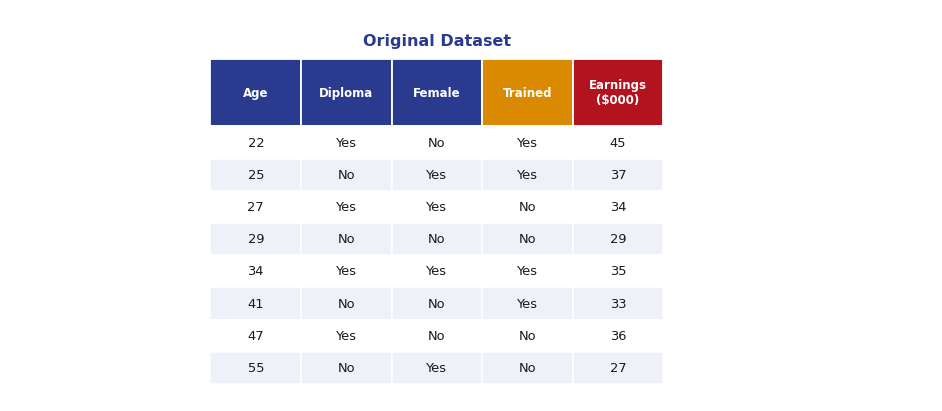

In [43]:
fig, ax = frame((10.8, 4.6), (-2.6, 9.4), (-5.3, 0.75))
t = data_table(ax, ROWS, left=0.0, top=0.0, caption="Original Dataset",
               head_colors=COLHEAD)

### What Sits in a Leaf

- A regression tree leaf holds the <b style="color:#73000A;">average earnings</b> of everyone in it
- A causal tree leaf holds a <b style="color:#73000A;">difference</b>: the average earnings of those who trained, minus the average earnings of those who did not
- Start with everybody in one leaf

In [44]:
print("trained:  %s   average %.1f" % (lst(ALL, True), EARN[TRN].mean()))
print("did not:  %s   average %.1f" % (lst(ALL, False), EARN[~TRN].mean()))
print()
print("effect = %.1f - %.1f = %+.1f" % (EARN[TRN].mean(), EARN[~TRN].mean(), effect(ALL)))

trained:  45, 37, 35, 33   average 37.5
did not:  34, 29, 36, 27   average 31.5

effect = 37.5 - 31.5 = +6.0


### Candidate 1: Diploma

Everyone with a diploma goes left, everyone without goes right, and each
leaf gets its own effect.

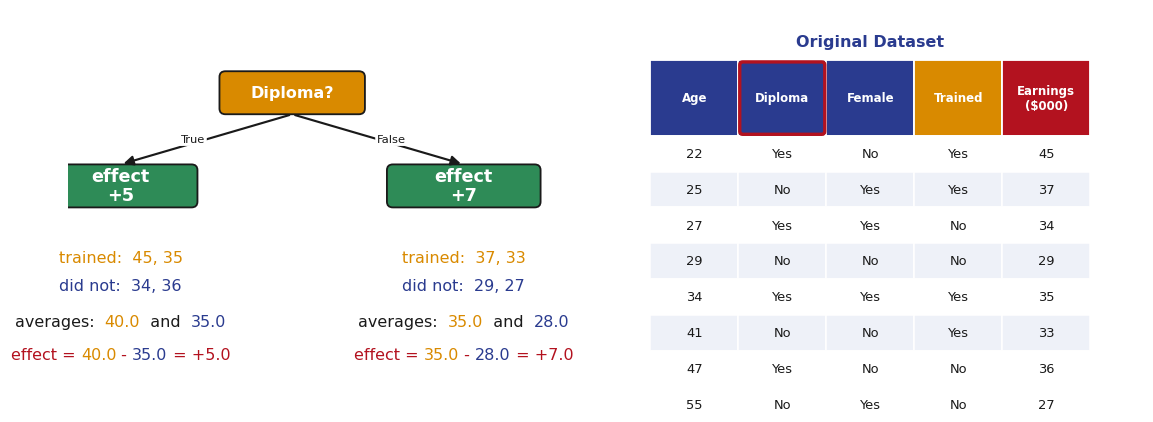

In [45]:
fig, ax = split_picture("Diploma?", DIP, ~DIP, ring_col=1)
for x, m in ((-5.9, DIP), (-1.3, ~DIP)):
    went, didnt = EARN[m & TRN].mean(), EARN[m & ~TRN].mean()
    colored_note(ax, x, -3.45, [("averages:  ", None), ("%.1f" % went, chh.ACCENT),
                                ("  and  ", None), ("%.1f" % didnt, chh.MADRID)], fs=10.5)
    colored_note(ax, x, -3.90, [("effect = ", chh.FITLINE), ("%.1f" % went, chh.ACCENT),
                                (" - ", chh.FITLINE), ("%.1f" % didnt, chh.MADRID),
                                (" = %+.1f" % effect(m), chh.FITLINE)], fs=10.5)

### Candidate 2: Female

Same arithmetic, a different question. The two effects land at <b style="color:#73000A;">+5.5</b> and
<b style="color:#73000A;">+6.5</b>, closer together than diploma's.

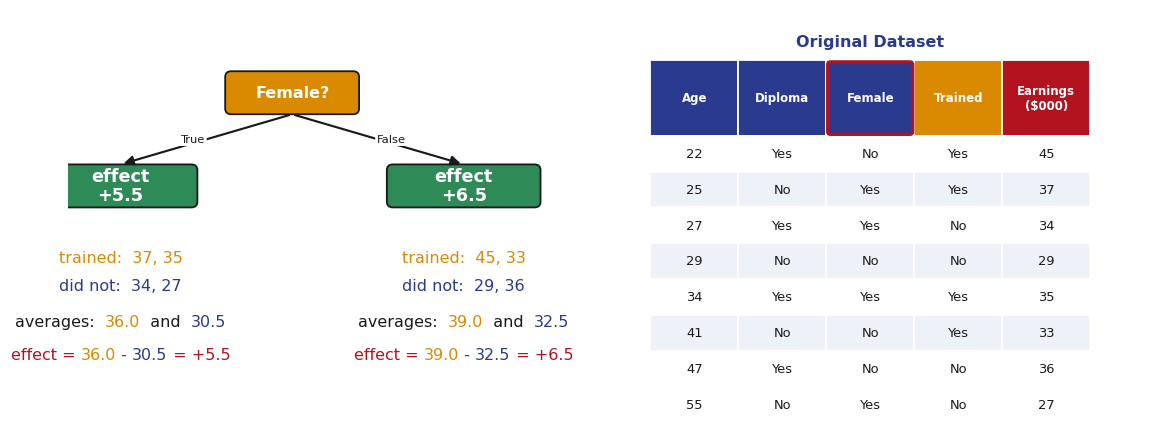

In [46]:
fig, ax = split_picture("Female?", FEM, ~FEM, ring_col=2)
for x, m in ((-5.9, FEM), (-1.3, ~FEM)):
    went, didnt = EARN[m & TRN].mean(), EARN[m & ~TRN].mean()
    colored_note(ax, x, -3.45, [("averages:  ", None), ("%.1f" % went, chh.ACCENT),
                                ("  and  ", None), ("%.1f" % didnt, chh.MADRID)], fs=10.5)
    colored_note(ax, x, -3.90, [("effect = ", chh.FITLINE), ("%.1f" % went, chh.ACCENT),
                                (" - ", chh.FITLINE), ("%.1f" % didnt, chh.MADRID),
                                (" = %+.1f" % effect(m), chh.FITLINE)], fs=10.5)

### Candidate 3: Age Is Numeric

- Sort the ages, and for each adjacent pair take their mean: 22 and 25 give 23.5
- Eight people give seven candidate cuts

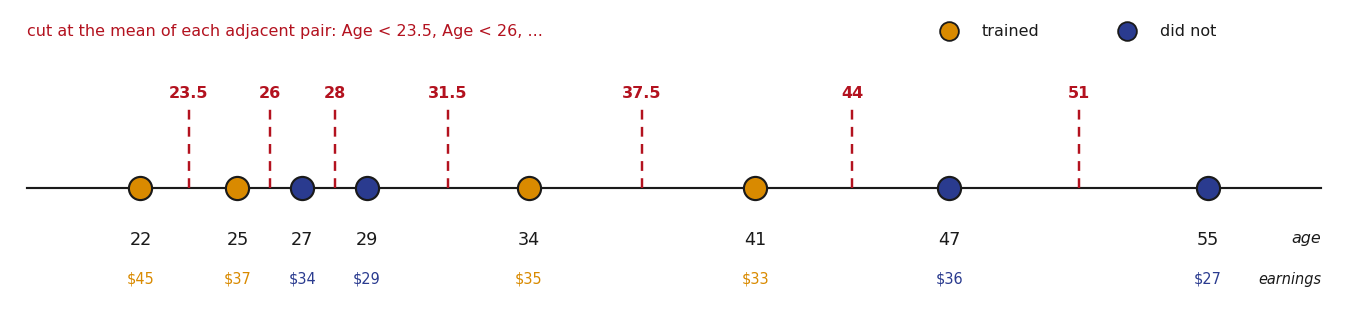

In [47]:
fig, ax = plt.subplots(figsize=(12.6, 3.4), dpi=110)
fig.patch.set_facecolor("white"); ax.set_facecolor("white")
ax.set_xlim(18, 59); ax.set_ylim(-1.35, 1.75); ax.axis("off")
ax.plot([18.5, 58.5], [0, 0], color=chh.INK, lw=1.4, zorder=1)

# the eight people, each at their age: orange trained, blue did not
for a, t, e in zip(AGE, TRN, EARN):
    ax.scatter(a, 0, s=230, zorder=4, facecolor=chh.ACCENT if t else chh.MADRID,
               edgecolor=chh.INK, lw=1.4)
    ax.text(a, -0.42, "%.0f" % a, ha="center", va="top", fontsize=11.5, color=chh.INK)
    ax.text(a, -0.82, "$%.0f" % e, ha="center", va="top", fontsize=9.5,
            color=chh.ACCENT if t else chh.MADRID)

# one dashed cut at the mean of each adjacent pair, with the question it asks
for k, c in enumerate(midpoints(AGE)):
    ax.plot([c, c], [-0.00, 0.78], color=chh.FITLINE, lw=1.6, ls=(0, (4, 3)), zorder=2)
    ax.text(c, 0.86 if k % 2 == 0 else 0.86, "%g" % c, ha="center", va="bottom",
            fontsize=10.5, color=chh.FITLINE, weight="bold")
ax.text(18.5, 1.55, "cut at the mean of each adjacent pair: Age < 23.5, Age < 26, ...", va="center",
        fontsize=10.5, color=chh.FITLINE)

ax.scatter([47.0], [1.55], s=150, facecolor=chh.ACCENT, edgecolor=chh.INK, lw=1.2, clip_on=False)
ax.text(48.0, 1.55, "trained", va="center", fontsize=10.5, color=chh.INK)
ax.scatter([52.5], [1.55], s=150, facecolor=chh.MADRID, edgecolor=chh.INK, lw=1.2, clip_on=False)
ax.text(53.5, 1.55, "did not", va="center", fontsize=10.5, color=chh.INK)
ax.text(58.5, -0.42, "age", ha="right", va="top", fontsize=10.5, color=chh.INK, style="italic")
ax.text(58.5, -0.82, "earnings", ha="right", va="top", fontsize=9.5, color=chh.INK, style="italic")
fig.tight_layout()

### Take the First One: Age < 23.5

One person goes left, and they trained. Nobody on that side did not, so
there is <b style="color:#73000A;">nothing to compare</b> and no effect to write in the leaf.

A cut is only a candidate if both sides hold someone who trained and someone
who did not.

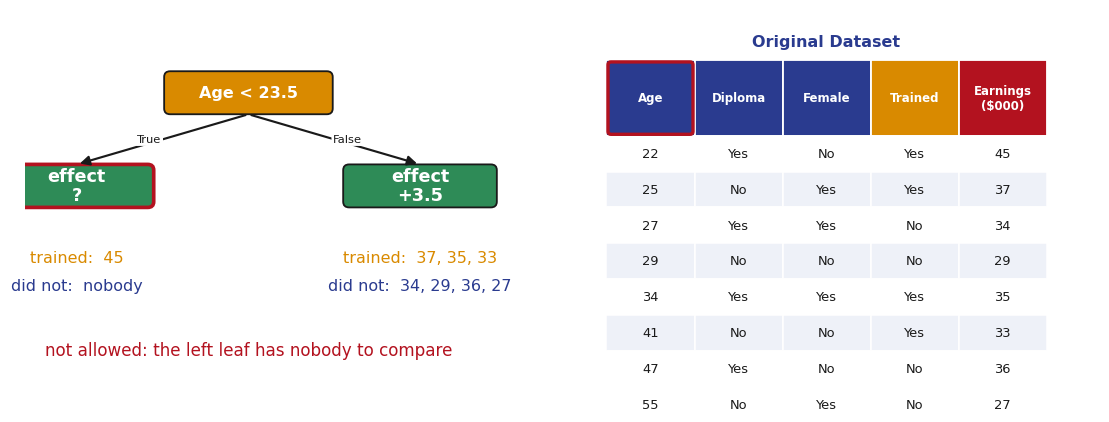

In [48]:
fig, ax = split_picture("Age < 23.5", AGE < 23.5, AGE >= 23.5, ring_col=0,
                        note_text="not allowed: the left leaf has nobody to compare")

### Age < 26

Two people go left now, 22 and 25, and <b style="color:#73000A;">both of them trained</b>. Still
nobody on that side to compare them with, so this cut is refused as well.

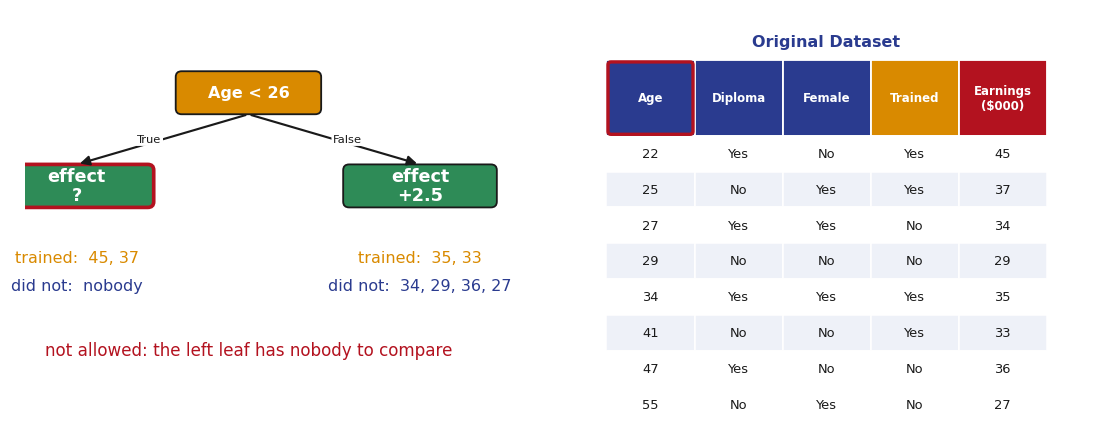

In [49]:
fig, ax = split_picture("Age < 26", AGE < 26, AGE >= 26, ring_col=0,
                        note_text="not allowed: the left leaf has nobody to compare")

### Age < 28

Three people go left and five go right. Both sides have someone who trained
and someone who did not, so both leaves get an effect: <b style="color:#73000A;">+7</b> and <b style="color:#73000A;">+3.33</b>.

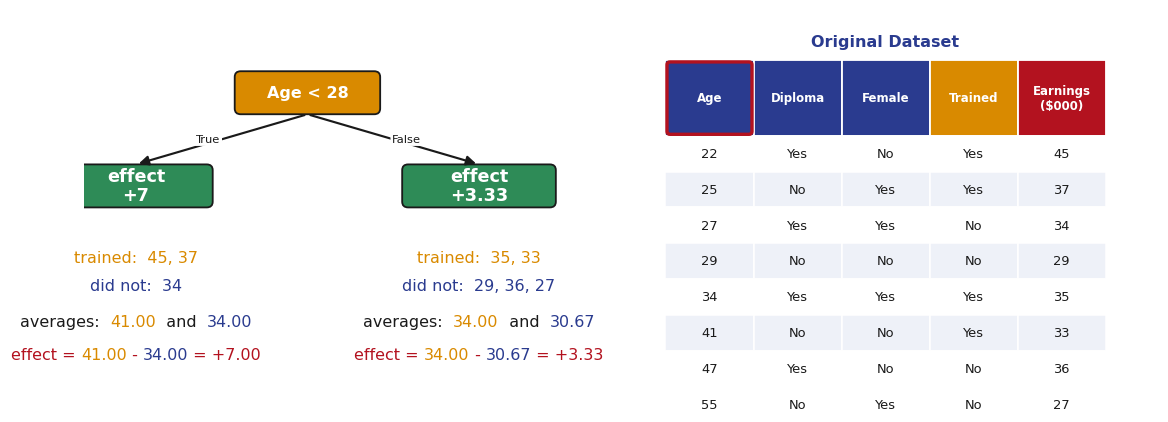

In [50]:
fig, ax = split_picture("Age < 28", AGE < 28, AGE >= 28, ring_col=0)
for x, m in ((-5.9, AGE < 28), (-1.3, AGE >= 28)):
    went, didnt = EARN[m & TRN].mean(), EARN[m & ~TRN].mean()
    colored_note(ax, x, -3.45, [("averages:  ", None), ("%.2f" % went, chh.ACCENT),
                                ("  and  ", None), ("%.2f" % didnt, chh.MADRID)], fs=10.5)
    colored_note(ax, x, -3.90, [("effect = ", chh.FITLINE), ("%.2f" % went, chh.ACCENT),
                                (" - ", chh.FITLINE), ("%.2f" % didnt, chh.MADRID),
                                (" = %+.2f" % effect(m), chh.FITLINE)], fs=10.5)

### Age < 31.5

Four and four. The effects come out at <b style="color:#73000A;">+9.5</b> and <b style="color:#73000A;">+2.5</b>, the furthest
apart of anything so far.

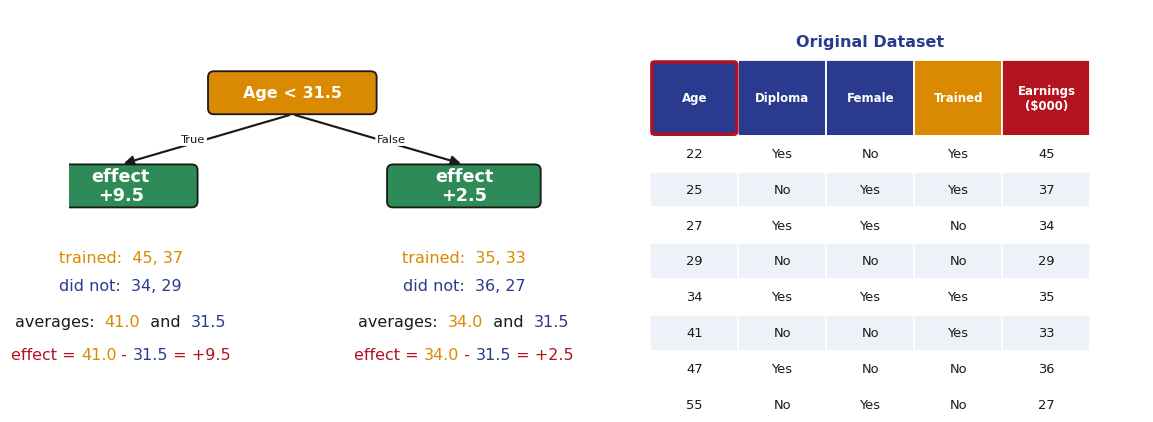

In [51]:
fig, ax = split_picture("Age < 31.5", AGE < 31.5, AGE >= 31.5, ring_col=0)
for x, m in ((-5.9, AGE < 31.5), (-1.3, AGE >= 31.5)):
    went, didnt = EARN[m & TRN].mean(), EARN[m & ~TRN].mean()
    colored_note(ax, x, -3.45, [("averages:  ", None), ("%.1f" % went, chh.ACCENT),
                                ("  and  ", None), ("%.1f" % didnt, chh.MADRID)], fs=10.5)
    colored_note(ax, x, -3.90, [("effect = ", chh.FITLINE), ("%.1f" % went, chh.ACCENT),
                                (" - ", chh.FITLINE), ("%.1f" % didnt, chh.MADRID),
                                (" = %+.1f" % effect(m), chh.FITLINE)], fs=10.5)

### Putting a Number on How Far Apart

Every candidate hands back two effects. The score is how far each leaf's
effect sits from the effect before the split, <b style="color:#73000A;">+6</b>, weighted by how many
people are in the leaf, and added up:

$$\text{gain} \;=\; n_{\text{left}}\,(\hat\tau_{\text{left}} - \hat\tau)^2 \;+\; n_{\text{right}}\,(\hat\tau_{\text{right}} - \hat\tau)^2$$

- Age < 31.5: $4 \times (9.5 - 6)^2 + 4 \times (2.5 - 6)^2 = 49 + 49 =$ <b style="color:#73000A;">98</b>
- Diploma: $4 \times (5 - 6)^2 + 4 \times (7 - 6)^2 = 4 + 4 =$ <b style="color:#73000A;">8</b>
- Female: $4 \times (5.5 - 6)^2 + 4 \times (6.5 - 6)^2 = 1 + 1 =$ <b style="color:#73000A;">2</b>

- Why n instead of a share: every candidate at this node would have the same denominator, so it wouldn't make a difference...

Squaring makes a leaf count for landing far from +6 in either direction.

### Score Every Age Cut

- One dot per candidate cut: the threshold along the bottom, the gain up the side
- Four of the seven are refused, since one side has nobody to compare
- The curve climbs, peaks at <b style="color:#73000A;">31.5</b>, and falls away

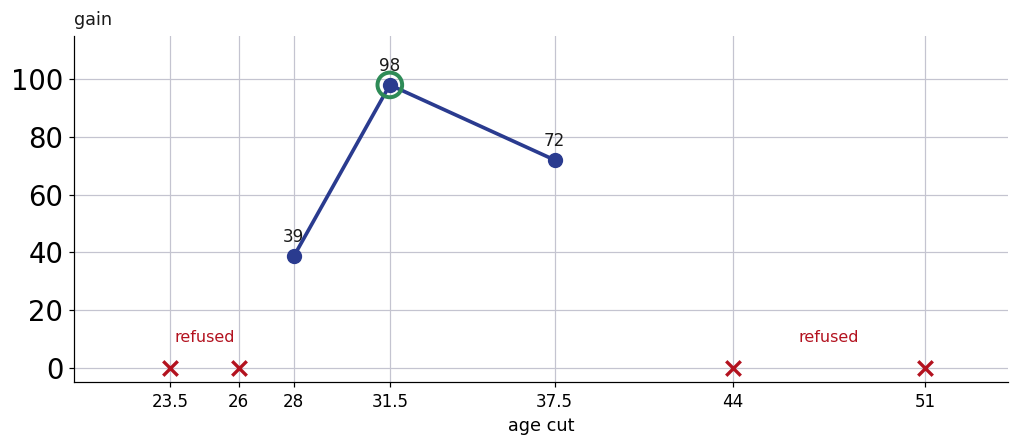

In [52]:
fig, ax = plt.subplots(figsize=(9.6, 4.4), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ok_x, ok_y, no_x = [], [], []
for c in midpoints(AGE):
    left, right = AGE < c, AGE >= c
    if allowed([left, right], least=1):
        ok_x.append(c)
        ok_y.append(gain([left, right]))
    else:
        no_x.append(c)
ax.plot(ok_x, ok_y, "-o", lw=2.4, ms=9, color=chh.MADRID, zorder=4)
ax.scatter(no_x, [0] * len(no_x), s=90, marker="x", color=chh.FITLINE, lw=2.2, zorder=5)
best = int(np.argmax(ok_y))
ax.scatter([ok_x[best]], [ok_y[best]], s=260, facecolors="none", edgecolors="#2E8B57",
           lw=2.6, zorder=6)
for x, y in zip(ok_x, ok_y):
    ax.text(x, y + 5, "%.0f" % y, ha="center", fontsize=11, color=chh.INK)
ax.text(np.mean(no_x[:2]), 9, "refused", ha="center", fontsize=10.5, color=chh.FITLINE)
ax.text(np.mean(no_x[2:]), 9, "refused", ha="center", fontsize=10.5, color=chh.FITLINE)
ax.set_xticks(midpoints(AGE))
ax.set_xticklabels(["%g" % v for v in midpoints(AGE)], fontsize=11)
ax.set_xlim(20, 54)
ax.set_ylim(-5, 115)
ax.set_xlabel("age cut", fontsize=11.5)
ax.text(0, 1.02, "gain", transform=ax.transAxes, ha="left", va="bottom",
        fontsize=11.5, color=chh.INK)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### The Scoreboard

- Each column nominates its own best question, and the biggest gain takes the root
- <b style="color:#73000A;">Age < 31.5</b> wins by a mile
- A regression tree on the same eight people would have asked about the <b style="color:#73000A;">diploma</b> first. It moves earnings by about 6, and the effect by 2

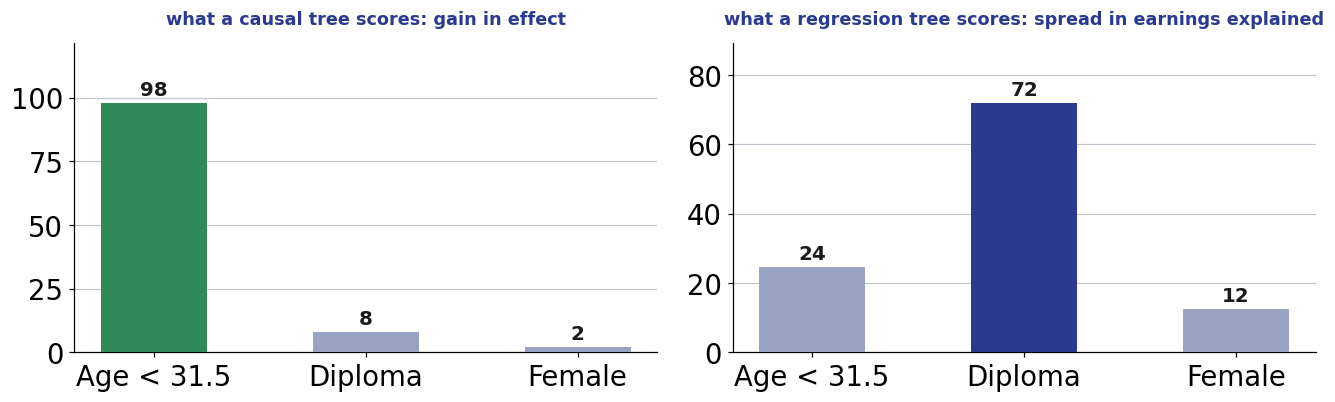

In [53]:
names = ["Age < 31.5", "Diploma", "Female"]
lefts = [AGE < 31.5, DIP, FEM]
gains = [gain([m, ~m]) for m in lefts]


def ssr_drop(left):
    tot = ((EARN - EARN.mean()) ** 2).sum()
    inside = sum(((EARN[m] - EARN[m].mean()) ** 2).sum() for m in (left, ~left))
    return tot - inside


drops = [ssr_drop(m) for m in lefts]
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0), dpi=110)
fig.patch.set_facecolor("white")
for ax, (ttl, vals, colr) in zip(axes, (("what a causal tree scores: gain in effect", gains, LEAF_FILL),
                                        ("what a regression tree scores: spread in earnings explained", drops, chh.MADRID))):
    ax.set_facecolor("white")
    ax.grid(True, axis="y", color=chh.GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    top = max(vals)
    bars = ax.bar(names, vals, width=0.5, zorder=4,
                  color=[colr if v == top else "#9AA2C2" for v in vals])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + top * 0.03, "%.0f" % v, ha="center",
                fontsize=13, color=chh.INK, weight="bold")
    ax.set_ylim(0, top * 1.24)
    ax.set_title(ttl, fontsize=11.5, color=chh.MADRID, weight="bold", pad=12)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
fig.tight_layout()

## Then Do It Again, Inside Each Group

- The four people under 31.5 get the same treatment: their own candidates, their own scores
- Female splits them into <b style="color:#73000A;">+3</b> and <b style="color:#73000A;">+16</b>, a gain of 169, bigger than the root's
- Each of those leaves holds one person who trained and one who did not

In [54]:
young = AGE < 31.5
for name, m in (("under 31.5, female", young & FEM), ("under 31.5, not female", young & ~FEM)):
    print("%-24s trained %s   did not %s   effect %s"
          % (name, lst(m, True), lst(m, False), fmt(effect(m))))
print()
print("gain from splitting the under 31.5 group on Female: %.0f" % gain([young & FEM, young & ~FEM]))

under 31.5, female       trained 37   did not 34   effect +3
under 31.5, not female   trained 45   did not 29   effect +16

gain from splitting the under 31.5 group on Female: 169


### Is That Good?

Is that a good thing???

- No. An effect computed from one person against one person is a guess, and the bigger the guess, the bigger the gain
- Keep going and every leaf is one pair, every effect is the difference between two people, and the tree has learned the eight, not the program
- Some rule has to stop it

### The Rule That Stops It

- Refuse any question that would leave a leaf with fewer than <b style="color:#73000A;">two</b> people who trained or fewer than two who did not
- With eight people both age groups have two and two, so they stay as they are, and the tree stops after one question
- On a real file the number is larger. The idea is the same: an effect needs a crowd on both sides

### The Fitted Causal Tree

A regression tree leaf holds a prediction of earnings. These leaves hold an
<b style="color:#73000A;">effect</b>. Written out as an estimated function:

$$\hat\tau(\text{age}) \;=\; \begin{cases} +9.5 & \text{age} < 31.5 \\ +2.5 & \text{age} \ge 31.5 \end{cases}$$

Diploma and female were offered and turned down. They move earnings, and the tree does not care; it is looking for what moves the <b style="color:#73000A;">effect</b>.

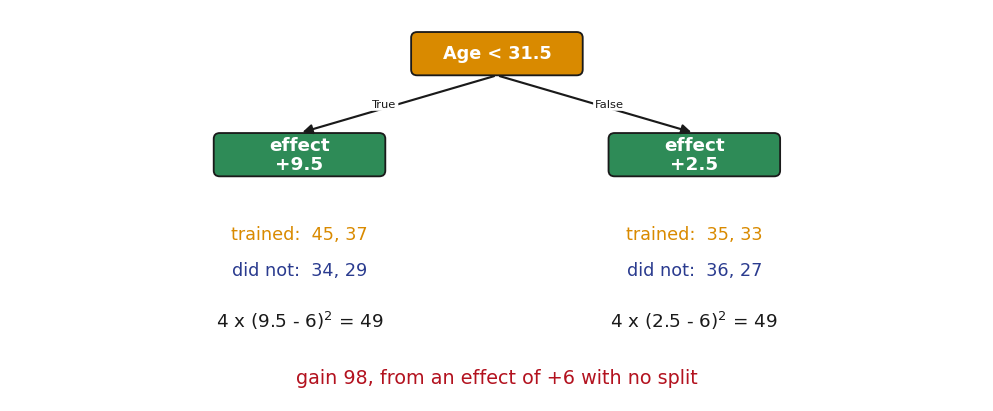

In [55]:
fig, ax = frame((11.4, 4.6), (-6.4, 6.4), (-4.3, 1.1))
node_box(ax, 0.0, 0.5, "Age < 31.5", fs=11.5)
for s, m, side in ((-1, AGE < 31.5, "True"), (1, AGE >= 31.5, "False")):
    x = s * 2.6
    link(ax, (0.0, 0.5), (x, -0.9), side)
    node_box(ax, x, -0.9, "effect\n%+g" % effect(m), kind="leaf", w=2.1, fs=12)
    note(ax, x, -2.0, "trained:  " + lst(m, True), fs=11.5, ha="center", color=chh.ACCENT)
    note(ax, x, -2.5, "did not:  " + lst(m, False), fs=11.5, ha="center", color=chh.MADRID)
    note(ax, x, -3.2, "%d x (%g - 6)$^2$ = %g" % (m.sum(), effect(m), m.sum() * (effect(m) - 6) ** 2),
         fs=12, ha="center")
note(ax, 0.0, -4.0, "gain 98, from an effect of +6 with no split", fs=12.5, ha="center",
     color=chh.FITLINE)

### Use It: Somebody New Walks In

A 26 year old with a diploma who has not trained. Run them down the tree:
26 is under 31.5, so the leaf says <b style="color:#73000A;">+9.5</b>. Send them.

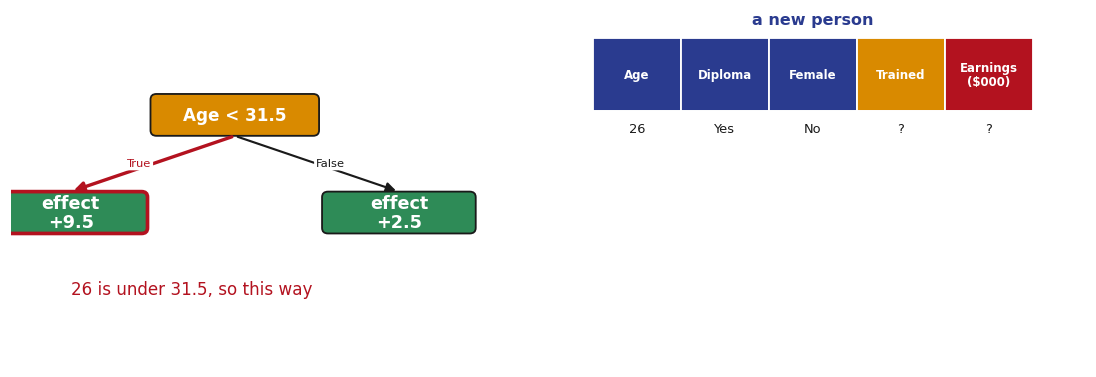

In [56]:
NEW = [("26", "Yes", "No", "?", "?")]
fig, ax = frame((12.6, 4.2), (-6.6, 7.8), (-3.6, 1.5))
data_table(ax, NEW, left=1.2, top=1.1, caption="a new person", head_colors=COLHEAD)
node_box(ax, -3.6, 0.0, "Age < 31.5", fs=11)
for s, m, side in ((-1, AGE < 31.5, "True"), (1, AGE >= 31.5, "False")):
    x = -3.6 + s * 2.2
    hot = s < 0
    link(ax, (-3.6, 0.0), (x, -1.4), side, red=hot)
    node_box(ax, x, -1.4, "effect\n%+g" % effect(m), kind="leaf", w=1.9, fs=11.5, ring=hot)
note(ax, -5.8, -2.5, "26 is under 31.5, so this way", fs=11, color=chh.FITLINE)

## One Tree Is Easy. It Is Also Not That Good

> Trees have one aspect that prevents them from being the ideal tool for
> predictive learning, namely inaccuracy.

- The cut landed at 31.5 because of where these eight people happened to be. Eight different people and it moves

### Step 1: Make a Bootstrapped Data Set

A bootstrapped data set is the <b style="color:#73000A;">same size</b> as the original. Draw rows out
of it at random, and you are allowed to draw the same row more than once.

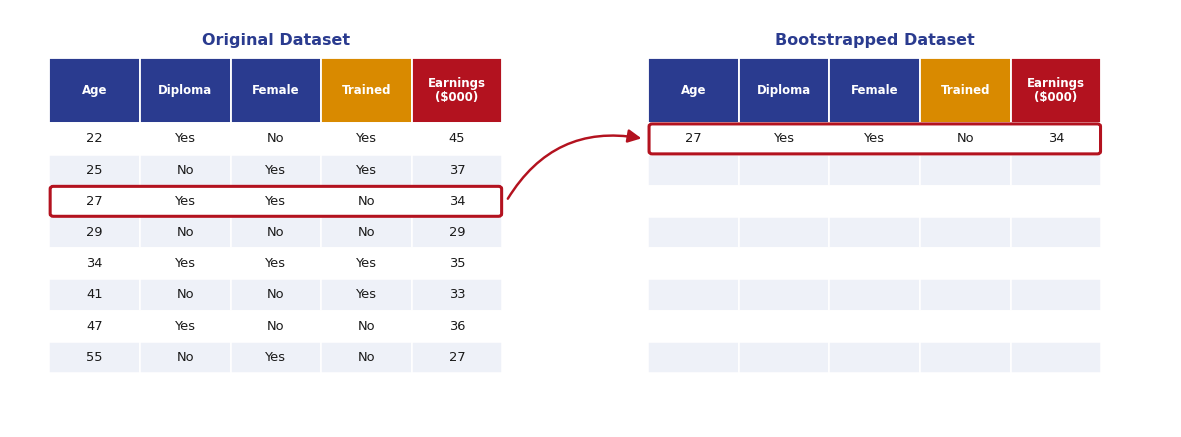

In [57]:
fig, ax = frame((13.6, 4.9), (-0.5, 14.6), (-5.9, 0.75))
L = data_table(ax, ROWS, left=0.0, top=0.0, ring_rows=[PICKS[0]],
               caption="Original Dataset", head_colors=COLHEAD)
R = data_table(ax, [BOOT[0]] + [BLANK] * 7, left=7.8, top=0.0, ring_rows=[0],
               caption="Bootstrapped Dataset", head_colors=COLHEAD)
curve(ax, (L["right"] + 0.05, L["row"](PICKS[0])), (R["left"] - 0.05, R["row"](0)), rad=-0.35)

### Keep Drawing Until You Have Eight

- Two rows came up twice, and two were never drawn
- We are bootstrapping WITH REPLACEMENT, so this is allowed

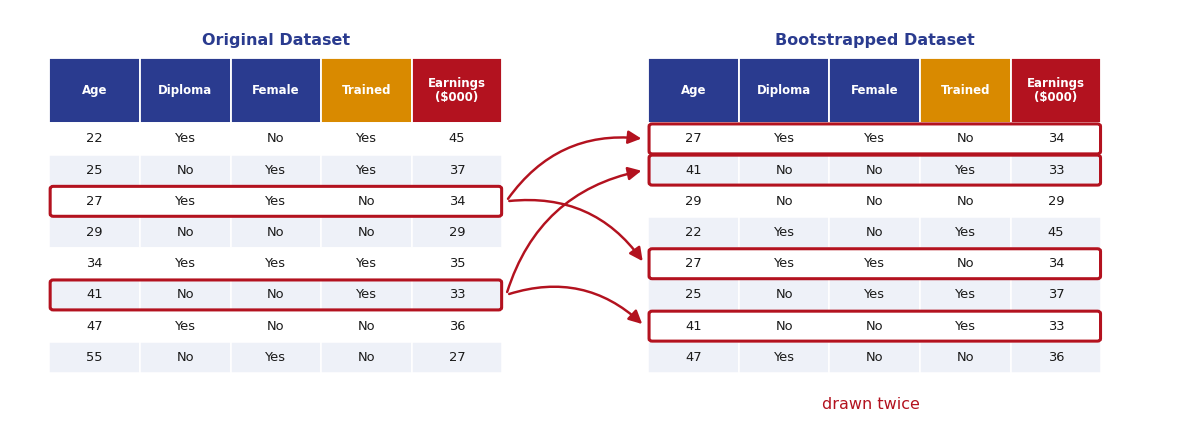

In [58]:
fig, ax = frame((13.6, 4.9), (-0.5, 14.6), (-5.9, 0.75))
dups = [k for k in range(8) if PICKS.count(PICKS[k]) > 1]
L = data_table(ax, ROWS, left=0.0, top=0.0, ring_rows=sorted(set(PICKS[k] for k in dups)),
               caption="Original Dataset", head_colors=COLHEAD)
R = data_table(ax, BOOT, left=7.8, top=0.0, ring_rows=dups,
               caption="Bootstrapped Dataset", head_colors=COLHEAD)
for k in dups:
    curve(ax, (L["right"] + 0.05, L["row"](PICKS[k])), (R["left"] - 0.05, R["row"](k)), rad=-0.3)
note(ax, R["left"] + 2.9, -5.55, "drawn twice", fs=10.5, ha="center", color=chh.FITLINE)

### Step 2: Build a Causal Tree, and Hide Most of the Columns

At <b style="color:#73000A;">every</b> node, pick a random two of the three columns and choose the
question from those two only. Here the draw came up age and diploma.

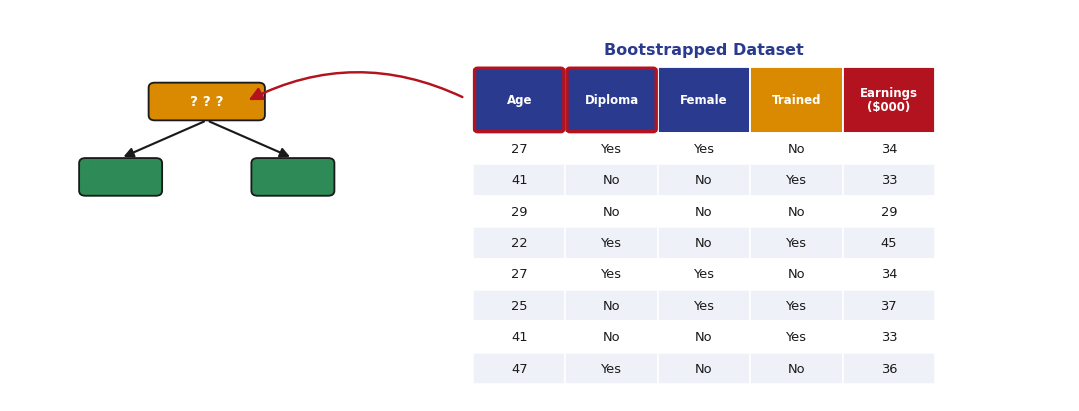

In [59]:
fig, ax = frame((12.4, 4.6), (-4.9, 8.6), (-5.3, 0.9))
T = data_table(ax, BOOT, left=1.0, top=0.0, ring_cols=[COLS[c] for c in OFFER],
               caption="Bootstrapped Dataset", head_colors=COLHEAD)
node_box(ax, -2.4, -0.55, "? ? ?")
for x in (-3.5, -1.3):
    link(ax, (-2.4, -0.55), (x, -1.75))
    node_box(ax, x, -1.75, "        ", kind="leaf", w=0.9)
curve(ax, (T["left"] - 0.1, -0.5), (-2.4 + 0.5, -0.55), rad=0.25)

### Age Wins the Root

- Same scoring as before, on the bootstrapped rows, with only the two offered columns in the running
- Once a column has been used, grey it out and move on

Age      best allowed question: Age < 28     gain 84.5
Diploma  best allowed question: none         gain 

the root asks: Age < 28


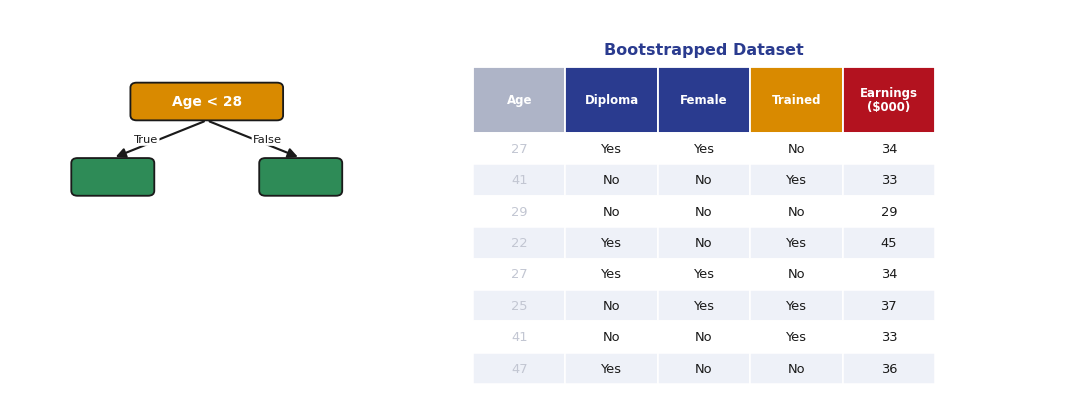

In [60]:
for c in OFFER:
    q = best_question(X8[PICKS], EARN[PICKS], TRN[PICKS], np.arange(8), [c], least=2)
    print("%-8s best allowed question: %-12s gain %s" % (c, "none" if q is None else q[1], "" if q is None else "%.1f" % q[0]))
print()
print("the root asks: %s" % ROOT[1])
fig, ax = frame((12.4, 4.6), (-4.9, 8.6), (-5.3, 0.9))
T = data_table(ax, BOOT, left=1.0, top=0.0, grey=[0], caption="Bootstrapped Dataset",
               head_colors=COLHEAD)
node_box(ax, -2.4, -0.55, ROOT[1])
for x, lab in ((-3.6, "True"), (-1.2, "False")):
    link(ax, (-2.4, -0.55), (x, -1.75), lab)
    node_box(ax, x, -1.75, "        ", kind="leaf", w=0.9)

### Do It Again at the Next Node

Two columns left, so draw two of them: diploma and female. Both questions
would leave a leaf with fewer than two who trained or two who did not, so
the rule refuses them and this node becomes a <b style="color:#73000A;">leaf</b>. Same on the other side.

Diploma  inside the Age < 28 group: no allowed question
Female   inside the Age < 28 group: no allowed question


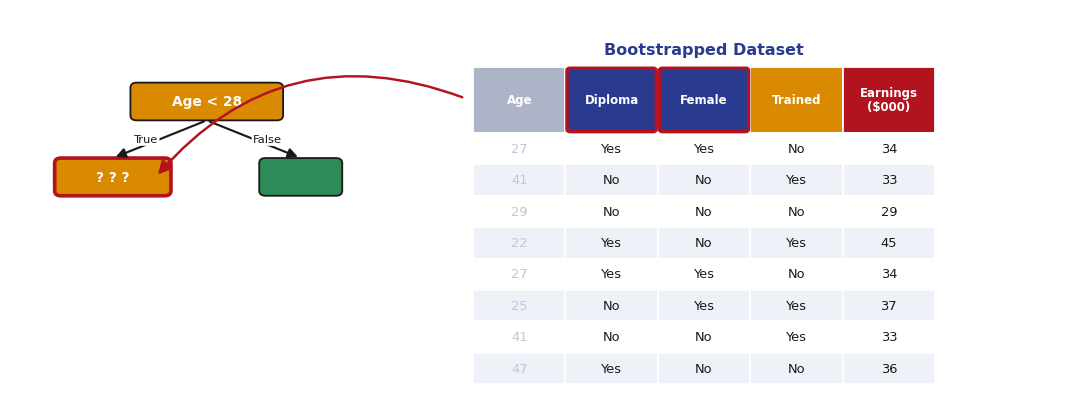

In [61]:
lm = ROOT[3]
for c in ("Diploma", "Female"):
    q = best_question(X8[PICKS], EARN[PICKS], TRN[PICKS], np.where(lm)[0], [c], least=2)
    print("%-8s inside the %s group: %s" % (c, ROOT[1], "no allowed question" if q is None else q[1]))
fig, ax = frame((12.4, 4.6), (-4.9, 8.6), (-5.3, 0.9))
T = data_table(ax, BOOT, left=1.0, top=0.0, grey=[0], ring_cols=[1, 2],
               caption="Bootstrapped Dataset", head_colors=COLHEAD)
node_box(ax, -2.4, -0.55, ROOT[1])
node_box(ax, -3.6, -1.75, "? ? ?", ring=True)
link(ax, (-2.4, -0.55), (-3.6, -1.75), "True")
link(ax, (-2.4, -0.55), (-1.2, -1.75), "False")
node_box(ax, -1.2, -1.75, "        ", kind="leaf", w=0.9)
curve(ax, (T["left"] - 0.1, -0.5), (-3.6 + 0.55, -1.75), rad=0.35)

### That Is One Tree

Built on a bootstrapped copy of the eight, choosing from a random two
columns at every node, with an effect in each leaf.

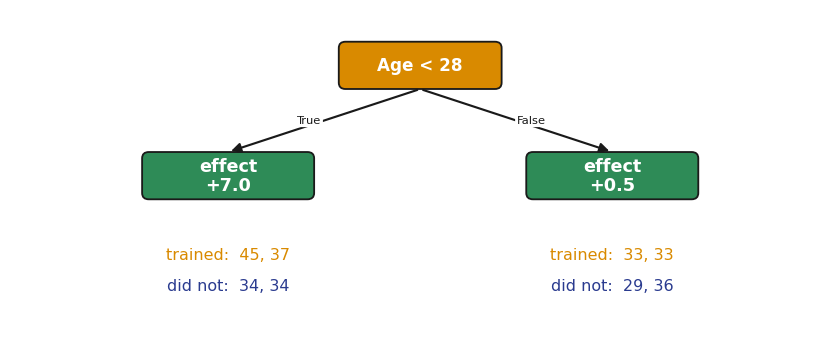

In [62]:
yb, tb = EARN[PICKS], TRN[PICKS]
fig, ax = frame((9.6, 4.0), (-4.9, 4.9), (-3.6, 0.7))
node_box(ax, 0.0, 0.0, ROOT[1], fs=11)
for s, m, side in ((-1, ROOT[3], "True"), (1, ROOT[4], "False")):
    x = s * 2.3
    link(ax, (0, 0), (x, -1.4), side)
    node_box(ax, x, -1.4, "effect\n%+.1f" % effect(m, yb, tb), kind="leaf", w=1.9, fs=11.5)
    note(ax, x, -2.4, "trained:  " + ", ".join("%.0f" % v for v in yb[m & tb]), fs=10.5,
         ha="center", color=chh.ACCENT)
    note(ax, x, -2.8, "did not:  " + ", ".join("%.0f" % v for v in yb[m & ~tb]), fs=10.5,
         ha="center", color=chh.MADRID)

### Now Go Back to Step 1 and Do It Again

A new bootstrap, a new set of random columns, a new tree. Do it hundreds of
times.

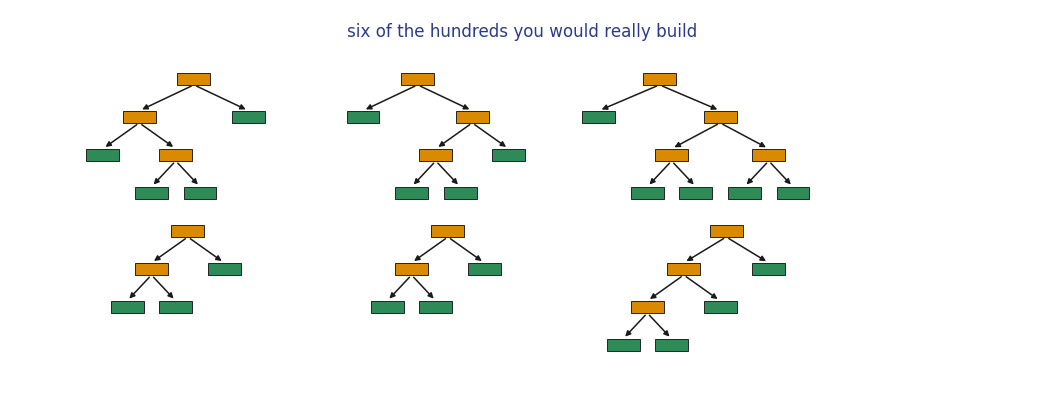

In [63]:
fig, ax = frame((12.0, 4.4), (-1.9, 9.9), (-4.0, 0.9))
for k in range(6):
    mini_tree(ax, (k % 3) * 3.0, -2.0 * (k // 3), seed=11 + 7 * k)
note(ax, 4.0, 0.62, "six of the hundreds you would really build", fs=11,
     ha="center", color=chh.MADRID)

### Using the Forest: Run the Person Down Every Tree

The 26 year old with a diploma goes down the first tree and lands in a leaf.
In lecture 9 the leaf held a vote. Here it holds a <b style="color:#73000A;">number</b>, and we keep
track of it.

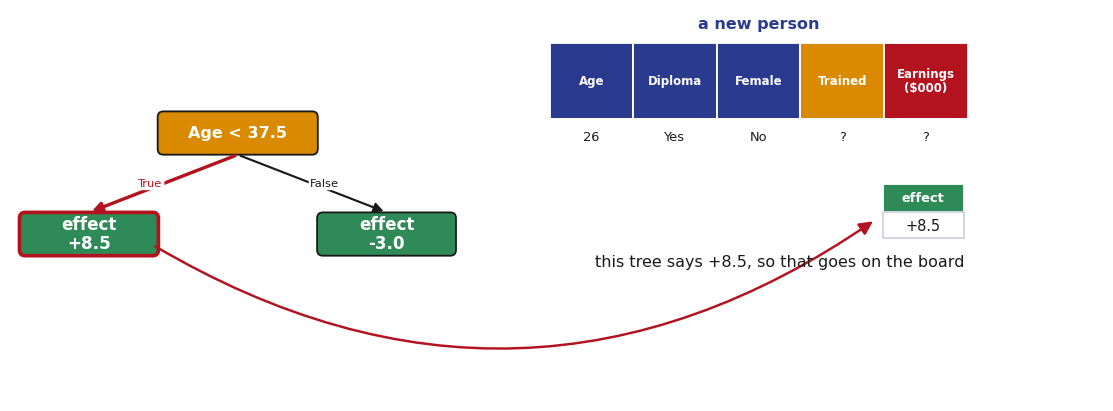

In [64]:
SIX = causal_forest(X8, EARN, TRN, trees=6, offer=2, least=2, seed=5)
NEWX = np.array([26.0, 1.0, 0.0])
ANS = [walk(tree, NEWX) for tree in SIX]
fig, ax = frame((12.8, 4.6), (-7.0, 8.4), (-3.9, 1.5))
data_table(ax, NEW, left=0.6, top=1.05, caption="a new person", head_colors=COLHEAD)
tree = SIX[0]
node_box(ax, -3.8, -0.2, tree.get("question", "no question allowed"), fs=10.5)
if "question" in tree:
    left_way = (NEWX[COLS[tree["column"]]] < float(tree["question"].split("< ")[1])
                if tree["column"] == "Age" else NEWX[COLS[tree["column"]]] == 1)
    for s, kid, side in ((-1, tree["left"], "True"), (1, tree["right"], "False")):
        x = -3.8 + s * 2.1
        hot = (s < 0) == left_way
        if hot:
            hx = x
        link(ax, (-3.8, -0.2), (x, -1.6), side, red=hot)
        node_box(ax, x, -1.6, "effect\n%+.1f" % kid["effect"], kind="leaf", w=1.8, fs=11, ring=hot)
v = effect_box(ax, 5.3, -0.9, ANS[:1], avg=False)
curve(ax, (hx + 0.9, -1.75), (v["left"] - 0.1, -1.4), rad=0.32)
note(ax, v["right"], v["bottom"] - 0.32, "this tree says %+.1f, so that goes on the board" % ANS[0], fs=10.5, ha="right")

### Average the Numbers

Six trees, six numbers. The forest's answer is their <b style="color:#73000A;">average</b>. Votes were
for a yes or no; an effect is a number, so the trees are averaged instead of
counted.

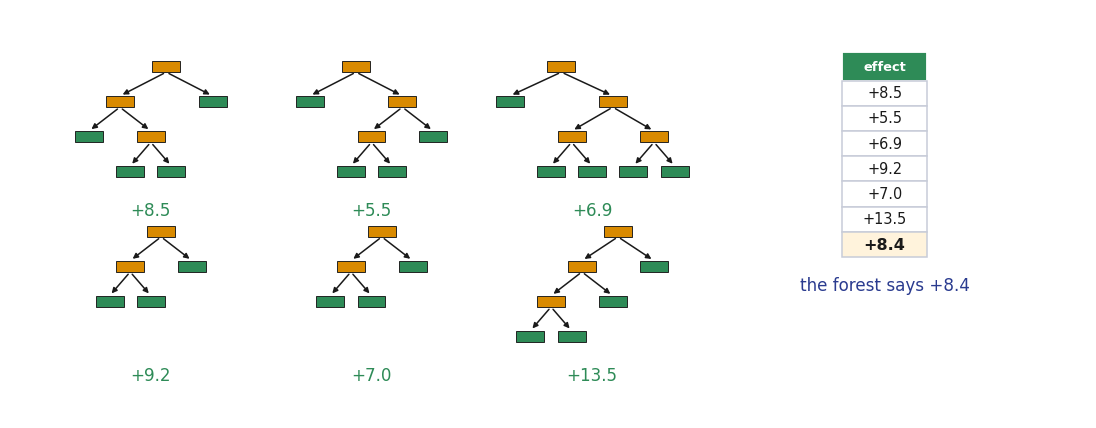

In [65]:
fig, ax = frame((12.6, 4.8), (-1.9, 12.7), (-5.0, 0.8))
for k in range(6):
    top = -2.35 * (k // 3)
    g = mini_tree(ax, (k % 3) * 3.0, top, seed=11 + 7 * k)
    note(ax, g["mid"], top - 2.05, "%+.1f" % ANS[k], fs=11, ha="center", color=LEAF_FILL)
v = effect_box(ax, 9.4, 0.2, ANS)
note(ax, v["left"] + 0.58, v["bottom"] - 0.4, "the forest says %+.1f" % np.mean(ANS), fs=11,
     ha="center", color=chh.MADRID)

### The Word for This Is Bagging

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Terminology</span>

- A <b style="color:#73000A;">random forest</b> is bagging plus hiding most of the columns at each node
- A <b style="color:#73000A;">causal forest</b> is a random forest whose trees put an effect in the leaf and split on how much it changes

### Out of Bag Has Nothing to Check Against

- In lecture 9 the rows never drawn tested the tree: run them down it, see if the label is right
- The thing this tree predicts is an <b style="color:#73000A;">effect</b>, and nobody has an observed effect. Each person trained or did not, never both
- So the third step of the recipe, scoring the forest on its out of bag rows, does not carry over as it stands
- Those never-drawn rows are still useful, and later on they are the whole fix

## A Bigger File

Four hundred people, the same rule as the eight with some noise on top, and
training handed out by <b style="color:#73000A;">coin flip</b>. Training is worth 8 under 30 and 2 from
30 on, a diploma 6, and being female costs 2.

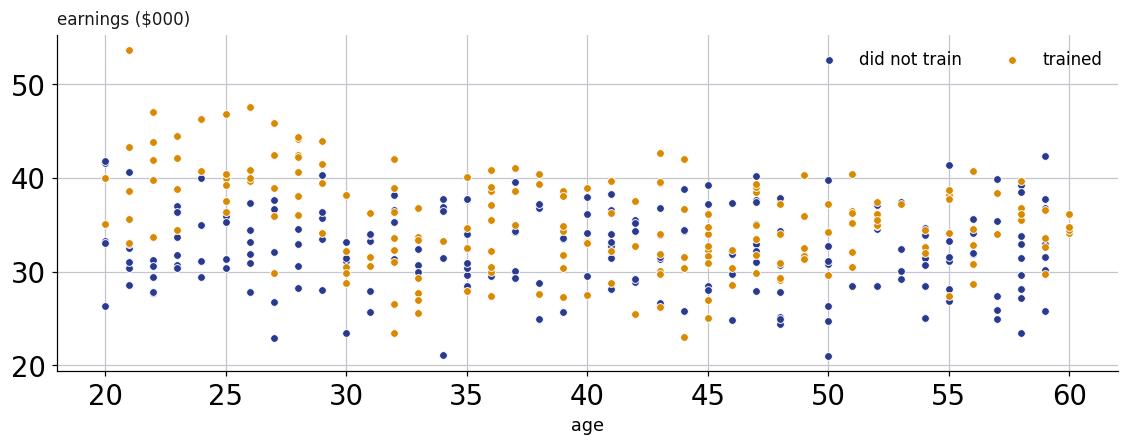

In [66]:
XB, YB, TB, TRUE = training_file(n=400, seed=3)
fig, ax = plt.subplots(figsize=(10.6, 4.4), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
for arm, col, lab in ((False, chh.MADRID, "did not train"), (True, chh.ACCENT, "trained")):
    m = TB == arm
    ax.scatter(XB[m, 0], YB[m], s=26, color=col, zorder=5, edgecolor="white", lw=0.6, label=lab)
ax.set_xlabel("age", fontsize=11.5)
ax.text(0, 1.02, "earnings ($000)", transform=ax.transAxes, ha="left", va="bottom",
        fontsize=11, color=chh.INK)
ax.legend(loc="upper right", fontsize=11, frameon=False, ncol=2)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### The Forest, Written Out

The recipe from this lecture, in one loop. Nothing installed here fits a
causal forest, and these lines are the idea anyway:

```python
def causal_forest(X, y, trained, trees=100, offer=2, least=5):
    forest = []
    for b in range(trees):
        rows = rng.integers(0, len(y), len(y))        # step 1: bootstrap the rows
        forest.append(grow(X[rows], y[rows], trained[rows],
                           offer=offer, least=least)) # step 2: a causal tree,
    return forest                                     #   `offer` columns per node

def forest_effect(forest, x):
    return np.mean([walk(tree, x) for tree in forest])   # average, not vote
```

`grow` is the tree from the first half: at every node draw `offer` columns, score every allowed question by its gain, keep the best, repeat in each leaf.

In [67]:
FOREST = causal_forest(XB, YB, TB, trees=100, offer=2, least=5, max_depth=6, seed=1)
ONE = FOREST[0]
for who, x in (("26, diploma, not female", [26.0, 1.0, 0.0]),
               ("26, no diploma, female", [26.0, 0.0, 1.0]),
               ("45, diploma, not female", [45.0, 1.0, 0.0]),
               ("45, no diploma, female", [45.0, 0.0, 1.0])):
    x = np.array(x)
    print("%-26s one tree %+5.1f    the forest %+5.1f    truth %+.0f"
          % (who, walk(ONE, x), forest_effect(FOREST, x), 8 if x[0] < 30 else 2))

26, diploma, not female    one tree  +8.0    the forest  +7.7    truth +8
26, no diploma, female     one tree  +6.7    the forest  +6.7    truth +8
45, diploma, not female    one tree  +3.2    the forest  +1.7    truth +2
45, no diploma, female     one tree  -0.1    the forest  +2.1    truth +2


### One Point on the Curve, Then Two More

- The curve on the next slide is for one kind of person, <b style="color:#73000A;">diploma, not female</b>, at every age from 20 to 60
- Each point is that person run down all hundred trees, one leaf number per tree, then the average
- Three of the forty-one points, worked: the first eight trees, then the average of all hundred

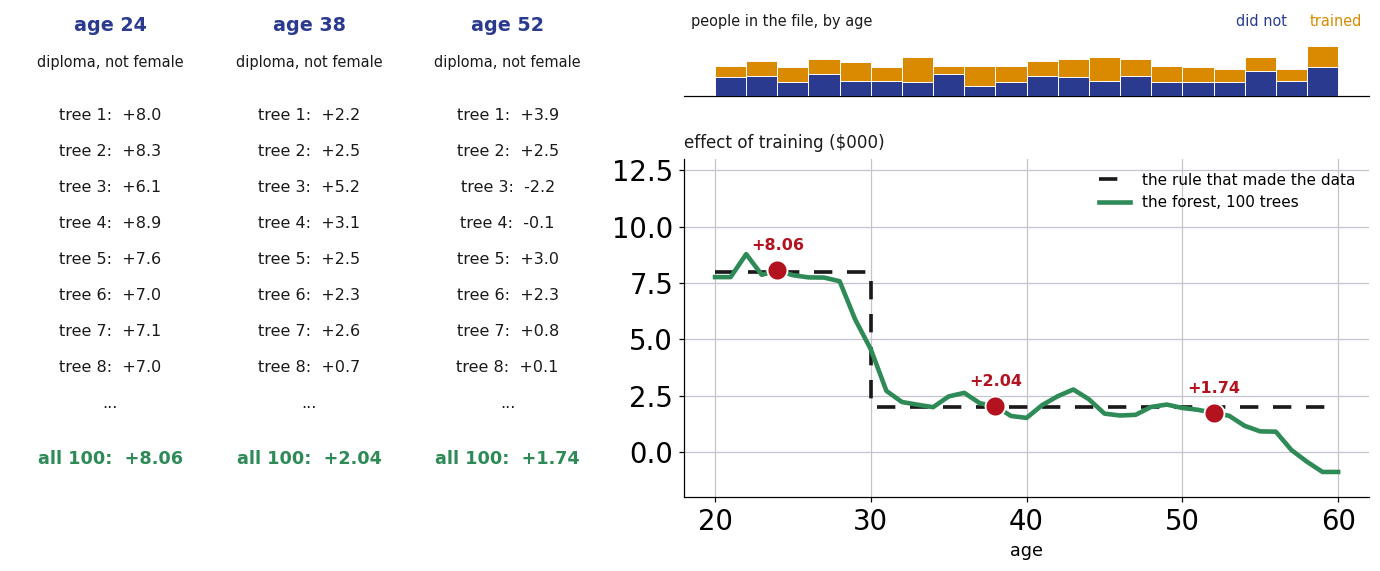

In [68]:
ages = np.arange(20, 61, 1.0)
grid = np.column_stack([ages, np.ones_like(ages), np.zeros_like(ages)])
avg = [forest_effect(FOREST, x) for x in grid]
SHOW = (24.0, 38.0, 52.0)
fig = plt.figure(figsize=(12.6, 5.2), dpi=110)
fig.patch.set_facecolor("white")
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.15], height_ratios=[1.0, 4.0], hspace=0.30, wspace=0.12)
ax = fig.add_subplot(gs[:, 0])
tx = fig.add_subplot(gs[0, 1])
bx = fig.add_subplot(gs[1, 1], sharex=tx)

# left: the first eight trees and the average of all hundred, for three people
ax.set_facecolor("white"); ax.axis("off"); ax.set_xlim(0, 3); ax.set_ylim(0, 1)
for k, a in enumerate(SHOW):
    x = np.array([a, 1.0, 0.0])
    vals = [walk(tree, x) for tree in FOREST]
    cx = k + 0.5
    ax.text(cx, 0.99, "age %g" % a, ha="center", va="top", fontsize=12.5, weight="bold", color=chh.MADRID)
    ax.text(cx, 0.91, "diploma, not female", ha="center", va="top", fontsize=9.5, color=chh.INK)
    for i, v in enumerate(vals[:8]):
        ax.text(cx, 0.80 - 0.074 * i, "tree %d:  %+.1f" % (i + 1, v), ha="center", va="top",
                fontsize=10.5, color=chh.INK)
    ax.text(cx, 0.80 - 0.074 * 8, "...", ha="center", va="top", fontsize=10.5, color=chh.INK)
    ax.text(cx, 0.80 - 0.074 * 9.5, "all 100:  %+.2f" % np.mean(vals), ha="center", va="top",
            fontsize=11.5, weight="bold", color=LEAF_FILL)

# top right: how many of the four hundred sit at each age, by arm
tx.set_facecolor("white")
counts, _, _ = tx.hist([XB[~TB, 0], XB[TB, 0]], bins=np.arange(20, 61, 2),
                       color=[chh.MADRID, chh.ACCENT], stacked=True, edgecolor="white", lw=0.6, zorder=3)
tx.set_ylim(0, 1.7 * counts[1].max())
tx.text(0.01, 0.97, "people in the file, by age", transform=tx.transAxes, ha="left", va="top",
        fontsize=9.5, color=chh.INK)
tx.text(0.99, 0.97, "trained", transform=tx.transAxes, ha="right", va="top", fontsize=9.5, color=chh.ACCENT)
tx.text(0.88, 0.97, "did not", transform=tx.transAxes, ha="right", va="top", fontsize=9.5, color=chh.MADRID)
tx.set_yticks([])
tx.tick_params(labelbottom=False, length=0)
for sp in ("top", "right", "left"):
    tx.spines[sp].set_visible(False)

# right: the curve, with those three points on it
bx.set_facecolor("white")
bx.grid(True, color=chh.GRID, lw=0.8, zorder=0)
bx.set_axisbelow(True)
bx.step(ages, np.where(ages < 30, 8, 2), where="post", color=chh.INK, lw=2.4, ls=(0, (5, 4)),
        zorder=4, label="the rule that made the data")
bx.plot(ages, avg, color=LEAF_FILL, lw=3.0, zorder=5, label="the forest, 100 trees")
for a in SHOW:
    v = forest_effect(FOREST, np.array([a, 1.0, 0.0]))
    bx.scatter([a], [v], s=170, color=chh.FITLINE, zorder=7, edgecolor="white", lw=1.2)
    bx.text(a, v + 0.9, "%+.2f" % v, ha="center", fontsize=10.5, color=chh.FITLINE, weight="bold")
bx.set_xlabel("age", fontsize=11.5)
bx.text(0, 1.02, "effect of training ($000)", transform=bx.transAxes, ha="left", va="bottom",
        fontsize=11, color=chh.INK)
bx.set_ylim(-2, 13)
bx.legend(loc="upper right", fontsize=10, frameon=False)
for sp in ("top", "right"):
    bx.spines[sp].set_visible(False)
fig.subplots_adjust(left=0.01, right=0.99, top=0.97, bottom=0.12)

### The Effect by Age

- One tree is a staircase with the steps in the wrong places
- A hundred trees averaged is close to the rule that made the data: <b style="color:#73000A;">8</b> under 30, <b style="color:#73000A;">2</b> after
- Still the same person, diploma and not female. The other three kinds of person come next

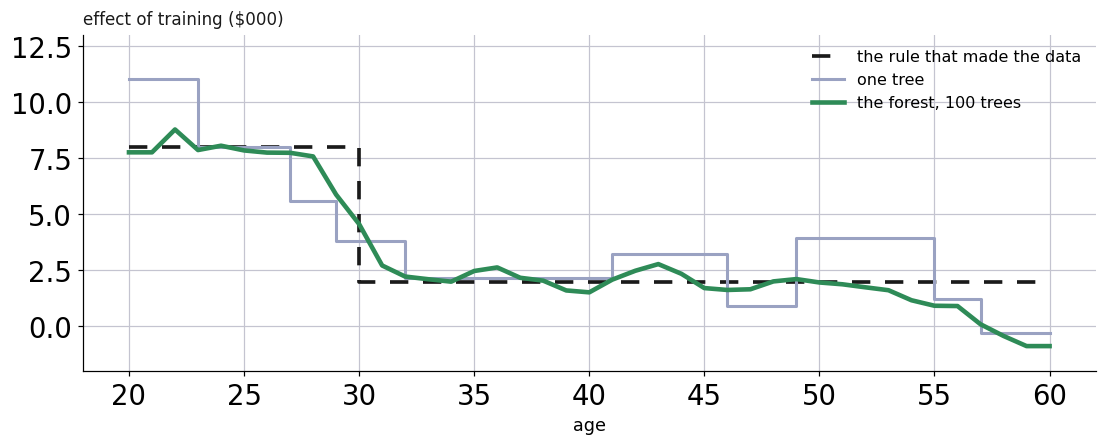

In [69]:
ages = np.arange(20, 61, 1.0)
grid = np.column_stack([ages, np.ones_like(ages), np.zeros_like(ages)])
one = [walk(ONE, x) for x in grid]
avg = [forest_effect(FOREST, x) for x in grid]
fig, ax = plt.subplots(figsize=(10.4, 4.4), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.step(ages, np.where(ages < 30, 8, 2), where="post", color=chh.INK, lw=2.4, ls=(0, (5, 4)),
        zorder=4, label="the rule that made the data")
ax.step(ages, one, where="post", color="#9AA2C2", lw=2.0, zorder=5, label="one tree")
ax.plot(ages, avg, color=LEAF_FILL, lw=3.0, zorder=6, label="the forest, 100 trees")
ax.set_xlabel("age", fontsize=11.5)
ax.text(0, 1.02, "effect of training ($000)", transform=ax.transAxes, ha="left", va="bottom",
        fontsize=11, color=chh.INK)
ax.set_ylim(-2, 13)
ax.legend(loc="upper right", fontsize=10.5, frameon=False)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### The Other Columns

- Diploma and female were offered at every node, and about a third of the questions in the forest ask about them
- Those questions split noise. The four kinds of person land on <b style="color:#73000A;">nearly the same line</b>, wobbling around the same step, because the rule that made the data has no diploma or female in the effect
- Had the effect depended on the diploma, the lines would pull apart, and the forest would have found that too

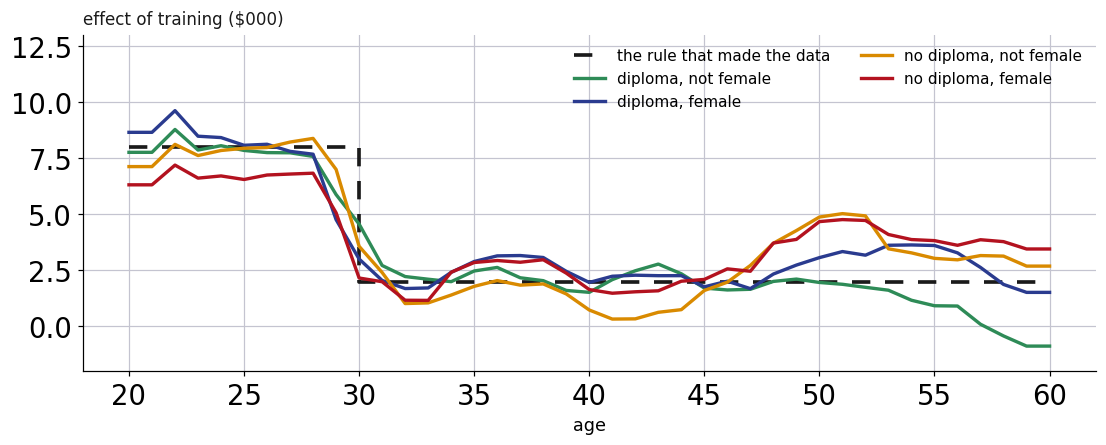

In [70]:
ages = np.arange(20, 61, 1.0)
fig, ax = plt.subplots(figsize=(10.4, 4.4), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.step(ages, np.where(ages < 30, 8, 2), where="post", color=chh.INK, lw=2.4, ls=(0, (5, 4)),
        zorder=4, label="the rule that made the data")
for d, f, col, lab in ((1, 0, LEAF_FILL, "diploma, not female"),
                       (1, 1, chh.MADRID, "diploma, female"),
                       (0, 0, chh.ACCENT, "no diploma, not female"),
                       (0, 1, chh.FITLINE, "no diploma, female")):
    grid = np.column_stack([ages, np.full_like(ages, d), np.full_like(ages, f)])
    ax.plot(ages, [forest_effect(FOREST, x) for x in grid], color=col, lw=2.2, zorder=5, label=lab)
ax.set_xlabel("age", fontsize=11.5)
ax.text(0, 1.02, "effect of training ($000)", transform=ax.transAxes, ha="left", va="bottom",
        fontsize=11, color=chh.INK)
ax.set_ylim(-2, 13)
ax.legend(loc="upper right", fontsize=10, frameon=False, ncol=2)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

## Additional Features Packages Include

- <b style="color:#73000A;">Honesty</b>: the one-against-one problem from the eight people
- <b style="color:#73000A;">Local centering</b>: the forest from last time, put to work inside the leaf
- The forest is a <b style="color:#73000A;">weighted average</b>: which rows the number came from
- <b style="color:#73000A;">Out of bag</b> rows, used for what they are good for
- A <b style="color:#73000A;">standard error</b>, and what it assumes

### 1. Honesty: Two Jobs, Two Halves

- "Is That Good?" came back. At eight people the two-and-two rule stopped the tree. At four hundred with a smaller least, it does not: leaves of two against two, picked because those four happened to look far apart
- The same rows <b style="color:#73000A;">choose</b> the question and <b style="color:#73000A;">fill in</b> the leaf. A question wins because its leaves look far apart, so the leaf effects it writes down are pushed out further than the truth
- The honest tree splits the rows in half. One half picks the questions. The other half, which had no say, writes the leaf effects
- A question is refused unless both leaves keep people of both arms in <b style="color:#73000A;">both halves</b>

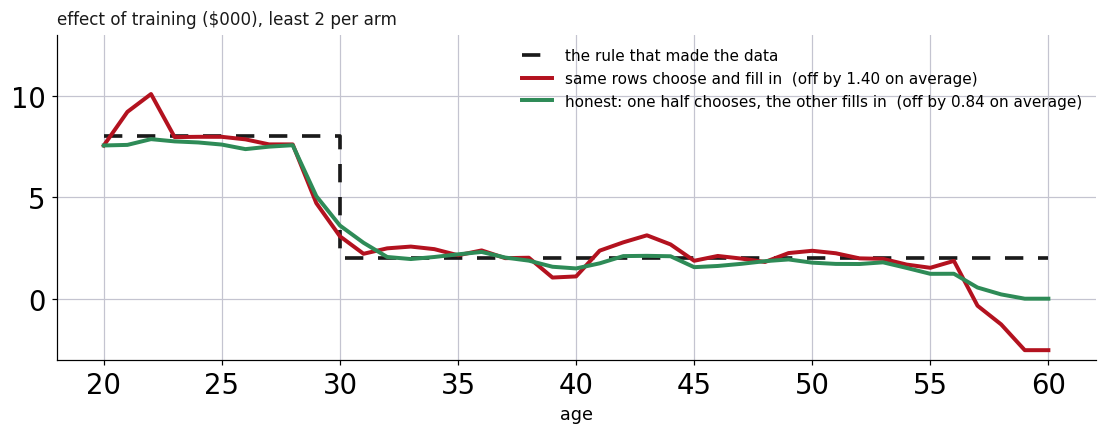

In [71]:
HON = honest_forest(XB, YB, TB, trees=100, offer=2, least=2, max_depth=6, seed=1)
ADA = causal_forest(XB, YB, TB, trees=100, offer=2, least=2, max_depth=6, seed=1)
ages = np.arange(20, 61, 1.0)
grid = np.column_stack([ages, np.ones_like(ages), np.zeros_like(ages)])
truth = np.where(ages < 30, 8.0, 2.0)
fig, ax = plt.subplots(figsize=(10.4, 4.3), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
ax.step(ages, truth, where="post", color=chh.INK, lw=2.4, ls=(0, (5, 4)), zorder=4,
        label="the rule that made the data")
for F, col, lab in ((ADA, chh.FITLINE, "same rows choose and fill in"),
                    (HON, LEAF_FILL, "honest: one half chooses, the other fills in")):
    est = np.array([forest_effect(F, x) for x in grid])
    ax.plot(ages, est, color=col, lw=2.6, zorder=6,
            label="%s  (off by %.2f on average)" % (lab, np.sqrt(np.mean((est - truth) ** 2))))
ax.set_xlabel("age", fontsize=11.5)
ax.text(0, 1.02, "effect of training ($000), least 2 per arm", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=11, color=chh.INK)
ax.set_ylim(-3, 13)
ax.legend(loc="upper right", fontsize=10, frameon=False)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### What Honesty Costs, and Buys Back

- Each tree now estimates from <b style="color:#73000A;">half</b> the rows, so one tree is noisier than before
- Each tree is also no longer allowed to flatter its own questions, and across a hundred trees that matters more
- The red line wanders between the steps and overshoots them. The green one sits closer to 8 and 2
- The packages turn honesty on by default. Where a slide today said "the rows in the leaf", read "the rows in the leaf that had no say in choosing it"

### 2. Local Centering: Take Out the Confounding First

So far training was a coin flip. Make the diploma holders <b style="color:#73000A;">sign up more often</b>,
and remember a diploma is worth 6 on its own.

- Everybody in one leaf, trained minus not, is now wrong before a single question is asked: the trained are more often diploma holders
- The tree can rescue itself by asking about the diploma, if it is offered, if the rule allows, in every branch
- Last time's fix is cheaper: predict earnings from $X$ and training from $X$ with cross-fit learners, and work with the <b style="color:#73000A;">residuals</b>
- The leaf then holds the slope of residual on residual, double ML computed inside the leaf, and the gain is the same formula on those leaf numbers

In [72]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict, KFold

XC, YC, TC, TRUEC = confounded_file(n=400, seed=3, lo=0.2, hi=0.7)
print("share who trained:  with a diploma %.2f   without %.2f" % (TC[XC[:, 1] == 1].mean(), TC[XC[:, 1] == 0].mean()))
print("everybody in one leaf, trained minus not:  %+.2f     truth, averaged over the 400:  %+.2f"
      % (YC[TC].mean() - YC[~TC].mean(), TRUEC.mean()))

kf = KFold(5, shuffle=True, random_state=1)
def rf():
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0)
YR = YC - cross_val_predict(rf(), XC, YC, cv=kf)                  # earnings residual
WR = TC.astype(float) - cross_val_predict(rf(), XC, TC.astype(float), cv=kf)   # training residual
print("everybody in one leaf, slope of residual on residual:  %+.2f" % (np.sum(WR * YR) / np.sum(WR ** 2)))

share who trained:  with a diploma 0.71   without 0.22
everybody in one leaf, trained minus not:  +6.84     truth, averaged over the 400:  +3.47
everybody in one leaf, slope of residual on residual:  +4.05


### What Centering Changes in the Tree

- Without it the root asks about the <b style="color:#73000A;">diploma</b> most of the time. Not because the effect differs by diploma, it does not, but because asking is the only way to undo the mix
- With it the diploma stops being interesting, and the questions go where the effect is
- On this file the uncentered forest mostly rescues itself, because the confounder is one column it can ask about. With twenty confounders and the same four hundred rows it cannot, and centering is what the packages do first

In [73]:
PLAIN = causal_forest(XC, YC, TC, trees=100, offer=2, least=5, max_depth=6, seed=1)
CENT = centered_forest(XC, YR, WR, TC, trees=100, offer=2, least=5, max_depth=6, seed=1)
print("share of trees whose first question is the diploma:   without centering %.0f%%    with %.0f%%"
      % (100 * asks_at_root(PLAIN, "Diploma"), 100 * asks_at_root(CENT, "Diploma")))
for who, x in (("26, diploma, not female", [26.0, 1.0, 0.0]), ("45, no diploma, female", [45.0, 0.0, 1.0])):
    x = np.array(x)
    print("%-26s without centering %+5.1f    with %+5.1f    truth %+.0f"
          % (who, forest_effect(PLAIN, x), forest_effect(CENT, x), 8 if x[0] < 30 else 2))

share of trees whose first question is the diploma:   without centering 61%    with 23%
26, diploma, not female    without centering  +8.8    with  +8.9    truth +8
45, no diploma, female     without centering  +2.0    with  +2.3    truth +2


### 3. The Forest Is a Weighted Average

Run the 26-year-old down a tree and they land in a leaf with some of the
rows. Do it in every tree and count:

$$\alpha_i \;=\; \frac{1}{B}\sum_{b=1}^{B} \frac{\mathbf{1}[\text{row } i \text{ shares the leaf}]}{\text{rows of the same arm in that leaf}}$$

- The forest's number is $\sum \alpha_i Y_i$ over the trained minus $\sum \alpha_i Y_i$ over the untrained. Same answer as averaging the leaves, <b style="color:#73000A;">same arithmetic rearranged</b>
- So a causal forest is a trained-minus-not with <b style="color:#73000A;">weights</b>, and the trees' only job was to decide who counts as a neighbour
- The weights are heavy on the under-30s and nearly zero past 35. Diploma and female were on offer at every node and the forest did not use them to pick neighbours

average of the hundred leaves  +7.748     weighted trained minus not  +7.748
rows with any weight: 162 of 400     share of the weight on people under 30: 94%


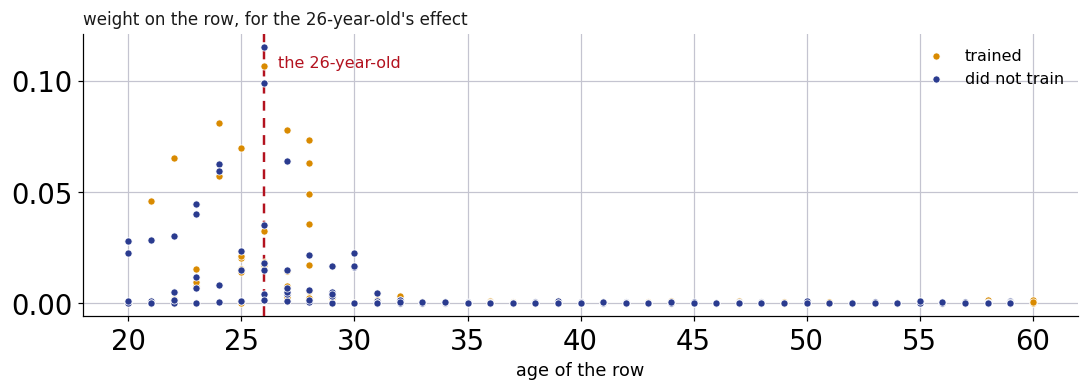

In [74]:
x26 = np.array([26.0, 1.0, 0.0])
aT, aC = forest_weights(FOREST, XB, TB, x26)
print("average of the hundred leaves  %+.3f     weighted trained minus not  %+.3f"
      % (forest_effect(FOREST, x26), np.sum(aT * YB) - np.sum(aC * YB)))
w = aT + aC
print("rows with any weight: %d of 400     share of the weight on people under 30: %.0f%%"
      % ((w > 0).sum(), 100 * w[XB[:, 0] < 30].sum() / w.sum()))

fig, ax = plt.subplots(figsize=(10.4, 3.9), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
for arm, col, lab in ((True, chh.ACCENT, "trained"), (False, chh.MADRID, "did not train")):
    m = TB == arm
    ax.scatter(XB[m, 0], (aT if arm else aC)[m], s=22, color=col, zorder=5, label=lab, edgecolor="white", lw=0.5)
ax.axvline(26, color=chh.FITLINE, lw=1.6, ls=(0, (4, 3)), zorder=3)
ax.text(26.6, ax.get_ylim()[1] * 0.92 if ax.get_ylim()[1] > 0 else 0.1, "the 26-year-old", color=chh.FITLINE, fontsize=10.5, va="top")
ax.set_xlabel("age of the row", fontsize=11.5)
ax.text(0, 1.02, "weight on the row, for the 26-year-old's effect", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=11, color=chh.INK)
ax.legend(loc="upper right", fontsize=10.5, frameon=False)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### 4. Out of Bag, Used for What It Is Good For

- Every row was left out of a third of the trees. Run it down those, average: that row's <b style="color:#73000A;">out of bag effect</b>, from trees that never saw it. This is the number the packages report for the training file
- There is still no observed effect to mark it against. There is a check: sort people by their out of bag number, cut into quarters, and inside each quarter compute trained minus not <b style="color:#73000A;">from the data</b>
- If the forest ranks people right, the data should climb with it. Here the top quarter is 96 of the 100 under-30s and the data put it near 7; the other three quarters are all over 30, where the truth is 2 everywhere, and the forest's ordering among them is noise, which the data also say
- The same out of bag numbers tune the dials. The packages try a few settings for the column count and the least per leaf and keep the one that fits best on rows it did not see

trees that never drew a given row: 22 to 53 of 100
quarter 1:  forest says  +1.0   trained minus not in the data  +2.9   (100 people, 0 under 30)
quarter 2:  forest says  +2.2   trained minus not in the data  +0.1   (100 people, 0 under 30)
quarter 3:  forest says  +3.7   trained minus not in the data  +2.5   (100 people, 2 under 30)
quarter 4:  forest says  +7.6   trained minus not in the data  +6.9   (100 people, 96 under 30)


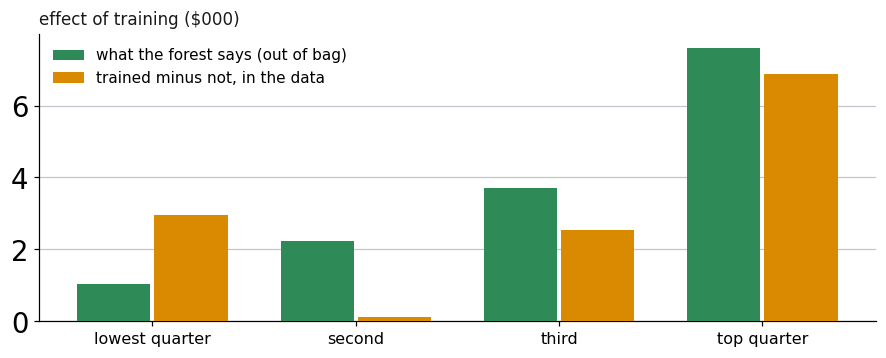

In [75]:
oob, cnt = oob_effects(FOREST, XB)
print("trees that never drew a given row: %.0f to %.0f of 100" % (cnt.min(), cnt.max()))
edges = np.quantile(oob, [0.25, 0.5, 0.75])
grp = np.digitize(oob, edges)
says, real, ns = [], [], []
for g in range(4):
    m = grp == g
    says.append(oob[m].mean())
    real.append(YB[m & TB].mean() - YB[m & ~TB].mean())
    ns.append(m.sum())
    print("quarter %d:  forest says %+5.1f   trained minus not in the data %+5.1f   (%d people, %d under 30)"
          % (g + 1, says[-1], real[-1], m.sum(), (m & (XB[:, 0] < 30)).sum()))

fig, ax = plt.subplots(figsize=(8.4, 3.6), dpi=110)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(True, axis="y", color=chh.GRID, lw=0.8, zorder=0)
ax.set_axisbelow(True)
pos = np.arange(4)
ax.bar(pos - 0.19, says, 0.36, color=LEAF_FILL, zorder=4, label="what the forest says (out of bag)")
ax.bar(pos + 0.19, real, 0.36, color=chh.ACCENT, zorder=4, label="trained minus not, in the data")
ax.set_xticks(pos)
ax.set_xticklabels(["lowest quarter", "second", "third", "top quarter"], fontsize=10.5)
ax.text(0, 1.02, "effect of training ($000)", transform=ax.transAxes, ha="left", va="bottom",
        fontsize=11, color=chh.INK)
ax.legend(loc="upper left", fontsize=10, frameon=False)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()

### 5. A Standard Error: Little Bags

- The spread of the hundred leaf numbers is <b style="color:#73000A;">not</b> a standard error. The trees share the same four hundred rows; redraw the rows and all hundred move together
- Little bags: draw <b style="color:#73000A;">half</b> the rows, grow five trees on that half. Do that twenty times
- The spread of the twenty group averages is how much the answer moves when the rows change, plus some noise from having only five trees in a group. The spread inside a group says how big that noise is, so subtract it
- The forest is a weighted average of earnings, and averages are normal, so the usual interval applies

In [76]:
est, se, between, within = little_bags(XB, YB, TB, x26, groups=20, per=5, offer=2, least=5, max_depth=6, seed=1)
print("the 26-year-old:  effect %+.2f   standard error %.2f   95%% interval %+.1f to %+.1f   (truth +8)"
      % (est, se, est - 1.96 * se, est + 1.96 * se))
print("spread of the hundred leaf numbers in the forest, for comparison: %.2f"
      % np.std([walk(tree, x26) for tree in FOREST], ddof=1))

# the check nobody can run on real data: draw the file afresh, refit, see how far the answer moves
fresh = []
for s in range(30):
    Xs, Ys, Ts, _ = training_file(n=400, seed=100 + s)
    fresh.append(forest_effect(causal_forest(Xs, Ys, Ts, trees=60, offer=2, least=5, max_depth=6, seed=s), x26))
print("thirty fresh files of 400, a forest on each: the answers have standard deviation %.2f" % np.std(fresh, ddof=1))

the 26-year-old:  effect +7.57   standard error 1.23   95% interval +5.2 to +10.0   (truth +8)
spread of the hundred leaf numbers in the forest, for comparison: 1.75
thirty fresh files of 400, a forest on each: the answers have standard deviation 1.29


### What It Assumes

- Nothing today made anything causal. Trained minus not inside a leaf is an effect only if, <b style="color:#73000A;">given $X$</b>, who trained is as good as random. Same assumption as every lecture since 15, and centering does not remove it, it only uses it better
- <b style="color:#73000A;">Overlap</b>, leaf by leaf: both arms present wherever an effect is written down. The refused cuts were this rule enforced one leaf at a time
- The forest finds who the effect differs for among the columns it was <b style="color:#73000A;">given</b>. A column it never saw cannot show up as heterogeneity
- Honesty, centering and little bags are what make the standard error believable. Without them the interval is for a number that was already pushed around by the choice of splits

### In Practice

- R: the `grf` package, `causal_forest(X, Y, W)`. Honesty on, centering on, little bags on, out of bag estimates from `predict()`, the dials tuned on out of bag rows: all by default
- Python: `econml`, `CausalForestDML`, the same recipe with the centering step spelled out as the double ML it is
- Neither is installed for this course. The loop from this lecture is what sits underneath both, and the five additions are the difference

## Key Ideas

- One average effect answers a question nobody asked; the city wants to know <b style="color:#73000A;">who to send</b>
- A causal tree is a decision tree with two changes: the leaf holds an <b style="color:#73000A;">effect</b>, trained minus not trained, and a split is scored by how far it pulls the two leaf effects apart
- A question is refused unless both leaves keep people who trained and people who did not
- Columns that move earnings and not the effect never get asked about
- A causal forest is the random forest recipe with that tree inside it: bootstrap the rows, hide most of the columns, grow hundreds, and <b style="color:#73000A;">average</b> the numbers
- <b style="color:#73000A;">Honesty</b>: one half of the rows chooses the questions, the other half writes the leaf effects, so a leaf cannot flatter the question that made it
- <b style="color:#73000A;">Centering</b>: residualize earnings and training on $X$ first, and the leaf holds the slope of residual on residual. Double ML inside the leaf
- The forest is a <b style="color:#73000A;">weighted average</b> of trained minus not; the trees only decide who counts as a neighbour
- Out of bag rows give every row an effect from trees that never saw it, a ranking check against the data, and a way to tune the dials
- A <b style="color:#73000A;">standard error</b> comes from little bags: half the rows at a time, groups of trees, the spread between groups with the spread inside taken out
- None of it makes anything causal. It assumes, as every lecture since 15 has, that treatment is as good as random given $X$